# Naive Bayes for Healthcare: what happens under the hood
Bernoulli Naive Bayes on an opioid use disorder (OUD) cohort, explained for clinicians

In the dataset and in the code, the target column is called `OD`: `OD = 1` means an OUD diagnosis was recorded. We keep that short label throughout so the text matches the code

**Learning objectives**
- Connect every number the model produces to Bayes' theorem (prior, likelihood, posterior)
- Translate model outputs into clinical language: pre-test probability, sensitivity, specificity, likelihood ratios, post-test probability
- Understand why the prior matters, and why changing it is the same as moving the decision threshold
- Use an external prior from research on the target population to correct a cohort whose OD rate is not representative
- Quantify how sure we are about what the model learned (Bayesian credible intervals)
- Check the "naive" assumption and see what it does to the probabilities (calibration)
- Compare Naive Bayes with logistic regression, a small decision tree, and Random Forest
- Turn a risk score into clinical actions and policies, and discuss fairness

**Roadmap:** Data → Model → Prior → Inside the model → How sure are we? → One patient → Is "naive" a problem? → Comparison → Our threshold in practice → Equity → How to improve

## 1. Naive Bayes in this context

We want the probability that a patient has a recorded opioid use disorder (`OD = 1`) *given* their features:

$$\underbrace{P(OD=1 \mid \text{Features})}_{\text{Posterior}} = \frac{\overbrace{P(\text{Features} \mid OD=1)}^{\text{Likelihood}} \times \overbrace{P(OD=1)}^{\text{Prior}}}{\underbrace{P(\text{Features})}_{\text{Evidence}}}$$

- **Prior** $P(OD=1)$: the base rate of OD *before* we look at the patient
- **Likelihood** $P(\text{Features} \mid OD=1)$: among patients *with* OD, how common is this combination of features
- **Evidence** $P(\text{Features})$: the same for both classes, so it only rescales the scores so they sum to 1 (this is what `predict_proba` does)

### 1.1. Why "naive"?
Estimating the probability of every *combination* of 20 yes/no features would need $2^{20} \approx 1$ million cells, far more than our 1,000 patients. So we assume **features are independent of each other once we know the class**:

$$P(\text{Features} \mid OD) = P(x_1 \mid OD) \times P(x_2 \mid OD) \times \dots \times P(x_{20} \mid OD)$$

This is almost never true in medicine (comorbidities cluster). In section 8 we check how wrong it is here and what it costs us.

### 1.2. The odds form (the version clinicians already use)
**Why divide the two equations?** Because odds are defined as the probability of the event divided by the probability of the alternative. We want to express Bayes' theorem as odds rather than probabilities.

Here, the **pre-test probability** is $P(OD=1)$, and the **pre-test odds** are $P(OD=1)/P(OD=0)$. After observing the features, the **post-test probability** is $P(OD=1 \mid \text{Features})$, and the **post-test odds** are $P(OD=1 \mid \text{Features})/P(OD=0 \mid \text{Features})$.

Bayes' theorem for each class is:

$$P(OD=1 \mid \text{Features}) = \frac{P(\text{Features} \mid OD=1)P(OD=1)}{P(\text{Features})}$$

$$P(OD=0 \mid \text{Features}) = \frac{P(\text{Features} \mid OD=0)P(OD=0)}{P(\text{Features})}$$

Now divide the two equations:

$$\frac{P(OD=1 \mid \text{Features})}{P(OD=0 \mid \text{Features})} = \frac{P(\text{Features} \mid OD=1)P(OD=1)/P(\text{Features})}{P(\text{Features} \mid OD=0)P(OD=0)/P(\text{Features})}$$

The same $P(\text{Features})$ appears in both equations, so it cancels.

$$\frac{P(OD=1 \mid \text{Features})}{P(OD=0 \mid \text{Features})} = \frac{P(OD=1)}{P(OD=0)} \times \frac{P(\text{Features} \mid OD=1)}{P(\text{Features} \mid OD=0)}$$

Now the three pieces are explicit:

$$\underbrace{\frac{P(OD=1 \mid \text{Features})}{P(OD=0 \mid \text{Features})}}_{\text{Post-test odds}} = \underbrace{\frac{P(OD=1)}{P(OD=0)}}_{\text{Pre-test odds}} \times \underbrace{\frac{P(\text{Features} \mid OD=1)}{P(\text{Features} \mid OD=0)}}_{\text{Combined LR (Bayes factor)}}$$

Under the Naive Bayes independence assumption, the combined LR is the product of one **individual LR** per feature:

$$\text{Post-test odds} = \text{Pre-test odds} \times \underbrace{LR_1 \times LR_2 \times \dots \times LR_{20}}_{\text{Combined LR (Bayes factor)}}$$

Each feature multiplies the odds by its own **individual likelihood ratio (LR)**. So the model's reasoning is a chain of multiplications we can follow one finding at a time (we do exactly that in section 7).

### 1.3. Translation table: model terms → clinical terms
Each row connects one quantity from its Bayesian definition to the model, its clinical interpretation, its example in this notebook, and the clinical intuition.

| Bayesian term | Model term | Clinical term | Example in this notebook | So what? / Clinical intuition |
|---|---|---|---|---|
| **Prior** | $P(OD=1)$ | Pre-test probability / prevalence | About 5% in the target population (external research); 18% in our cohort | **Where do we start?** Baseline risk before seeing this patient's features. A higher-risk population starts every patient at a higher risk |
| **Likelihood under OD** | $P(x=1 \mid OD=1)$ | Sensitivity of that finding | Low income (training set): 61% | **How common is this finding when OD is actually present?** High sensitivity means the feature often appears in patients with OD, but this alone does not tell us whether it distinguishes them from patients without OD |
| **Likelihood under no OD** | $P(x=1 \mid OD=0)$ | False-positive rate, $1-\text{specificity}$ | Low income (training set): 24% | **How common is the same finding without OD?** If this is also high, the finding is less useful because many patients without OD have it too |
| **Individual LR for a present finding** | $P(x=1 \mid OD=1) / P(x=1 \mid OD=0)$ | Positive likelihood ratio, LR+ | Low income: $0.61/0.24 \approx 2.6$ | **How much should a positive finding move us toward OD?** LR+ > 1 increases OD odds, LR+ = 1 adds no information. Here, low income multiplies the OD odds by about 2.6 |
| **Individual LR for an absent finding** | $P(x=0 \mid OD=1) / P(x=0 \mid OD=0)$ | Negative likelihood ratio, LR− | Low income absent: $(1-0.61)/(1-0.24)=0.39/0.76\approx0.51$ | **How much should absence of the finding move us away from OD?** LR− < 1 lowers OD odds. Here, not being low income multiplies the OD odds by about 0.51, roughly halving them |
| **Combined LR (Bayes factor)** | $LR_1 \times \dots \times LR_{20}$ | Overall strength of all findings together | Patient 20 in section 7: 2.79 | **How much do all findings together move the odds?** Prior odds × combined LR = posterior odds |
| **Posterior** | $P(OD=1 \mid x)$ | Post-test probability / patient risk | Per-patient predicted risk | **Where do we end after using the evidence?** The updated patient risk. We can then compare this probability with a clinical decision threshold to decide whether to act |

### 1.4. Bayes with counts (no formulas needed)
Before any code, let's do one Bayesian update by hand with the **whole cohort of 1,000 patients**:

| | Low income | Not low income | Total |
|---|---|---|---|
| OD = 1 | 116 | 65 | **181** |
| OD = 0 | 195 | 624 | 819 |
| Total | 311 | 689 | 1,000 |

- **Before** we know anything about a patient: 181 of 1,000 have OD, so the risk is **18%** (this cohort's prior; section 4 explains why we replace it with 5%)
- **After** we learn the patient is low income, we only look at the 311 low-income patients: 116 of them have OD, so the risk is **37%** (the posterior)
- One finding moved the risk from 18% to 37%. That is Bayesian updating: start from a base rate, then update with evidence

⚠️ Two questions that sound alike but are different:
- "Of the patients **with OD**, how many are low income?" 116 of 181 = **64%** (61% in the 750 training patients the model learns from) → this is the likelihood $P(\text{low income} \mid OD)$
- "Of the **low-income** patients, how many have OD?" 116 of 311 = **37%** → this is the posterior $P(OD \mid \text{low income})$

Mixing them up is one of the most common errors in medicine and in the news. Naive Bayes simply repeats this update for all 20 features at once.

### 1.5. Why Bernoulli Naive Bayes?
- `BernoulliNB`: binary features (yes/no). Note: it also uses the **absence** of a feature as evidence
- `GaussianNB`: continuous features assumed bell-shaped
- `CategoricalNB`: features with a few categories (e.g. binned days of supply)

Reference: [scikit-learn 1.9. Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html)

## 2. Setup and data

**Data dictionary** (same dataset as the Responsible AI toolbox notebook)
- `OD`: target. 1 = opioid use disorder (OUD) was recorded during a 2-year observation period, 0 = not recorded
- `Low_inc`: low income indicator (1 = low income)
- `SURG`: major surgery recorded during the 2-year period
- `rx_ds`: total opioid days of supply dispensed during the 2-year period. It counts what was dispensed, not what was taken. The source does not say whether overlapping prescriptions were removed, so values above 730 are possible
- `A` to `V`: yes/no diagnosis or condition-group indicators. They appear to follow ICD-10 chapter letters, e.g. `F` = mental and behavioural disorders, `M` = musculoskeletal, `R` = symptoms and abnormal findings, `S`/`T` = injury and poisoning, `V` = transport accidents

**Vocabulary:** a **finding/feature** is one input variable (clinical term / machine learning term). We use **flag** only for an alert that sends a patient to clinical review

⚠️ **The data is synthetic.** It is good for learning how the model works, not for drawing real clinical conclusions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, StratifiedKFold)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Binarizer
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (precision_score, recall_score, roc_auc_score,
                             average_precision_score, brier_score_loss,
                             ConfusionMatrixDisplay)

C_OD, C_NO = "#d95f02", "#7570b3"   # consistent colours: OD vs No OD
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
DATA_PATH = "Data/opiod_raw_data.csv"
df = pd.read_csv(DATA_PATH)
df.columns = [c.strip().replace(" ", "_") for c in df.columns]
df["OD"] = df["OD"].astype(int)

feature_cols = [c for c in df.columns if c not in ["ID", "OD"]]
rx_col = "rx_ds"
binary_cols = [c for c in feature_cols if c != rx_col]

print(f"Patients: {len(df)} | Features: {len(feature_cols)} | Missing values: {df.isna().sum().sum()}")
print(f"OD prevalence in the full cohort: {df['OD'].mean():.1%}")

Patients: 1000 | Features: 20 | Missing values: 0
OD prevalence in the full cohort: 18.1%


### 2.1. A quick look at `rx_ds` before we binarize it
The original pipeline turns days of supply into "any opioid supply (>0) yes/no". Let's check what that throws away.

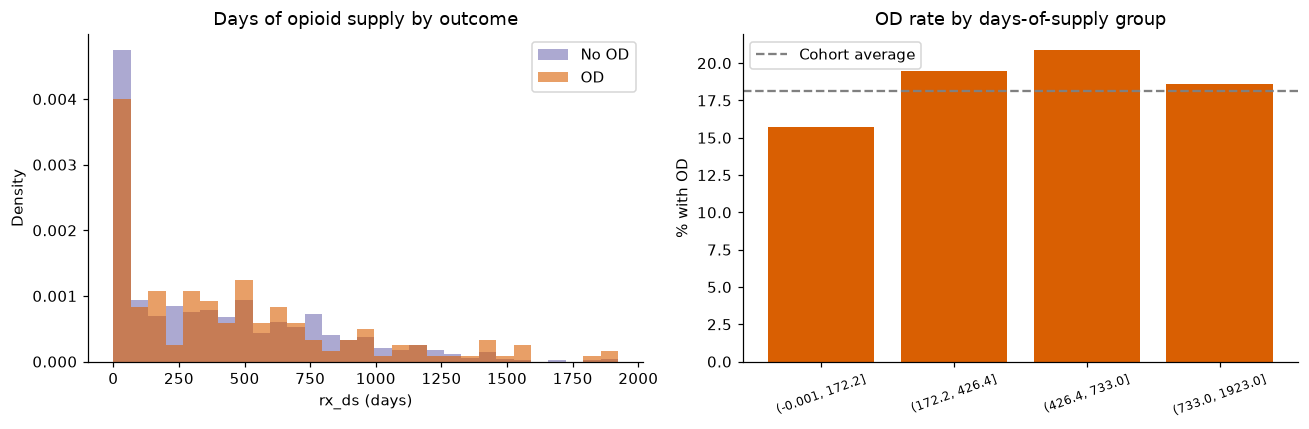

Share of patients with rx_ds > 0: 74.4%


,OD rate,patients
rx_ds,,
"(-0.001, 172.2]",15.8%,400
"(172.2, 426.4]",19.5%,200
"(426.4, 733.0]",20.9%,201
"(733.0, 1923.0]",18.6%,199


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, df[rx_col].max(), 30)
ax[0].hist(df.loc[df.OD == 0, rx_col], bins=bins, alpha=.6, color=C_NO, label="No OD", density=True)
ax[0].hist(df.loc[df.OD == 1, rx_col], bins=bins, alpha=.6, color=C_OD, label="OD", density=True)
ax[0].set(title="Days of opioid supply by outcome", xlabel="rx_ds (days)", ylabel="Density"); ax[0].legend()

q = pd.qcut(df[rx_col], 5, duplicates="drop")
rate = df.groupby(q, observed=True)["OD"].agg(["mean", "count"])
ax[1].bar(range(len(rate)), rate["mean"] * 100, color=C_OD)
ax[1].axhline(df.OD.mean() * 100, ls="--", c="grey", label="Cohort average")
ax[1].set_xticks(range(len(rate)), [str(i) for i in rate.index], rotation=20, fontsize=8)
ax[1].set(title="OD rate by days-of-supply group", ylabel="% with OD"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Share of patients with rx_ds > 0: {(df[rx_col] > 0).mean():.1%}")
display(rate.rename(columns={"mean": "OD rate", "count": "patients"}).style.format({"OD rate": "{:.1%}"}))

**What we see**
- About 3 in 4 patients have *some* opioid supply, so after binarizing, `rx_ds = 1` means "any supply", **not** "high supply"
- OD rate shows no clear trend with days of supply here (16% to 21%), so binarizing loses little in *this* dataset. In real data, dose and duration are strong risk factors, so always check before throwing a continuous variable away

**Timing matters** (same limitation as in the Responsible AI notebook): predictors and outcome come from the **same 2-year window**. This model ranks existing records by risk. It does **not** predict who will develop OD in the future


We use a stratified 75% training / 25% test split.

- **Test set (250 patients):** opened in section 3.2 for the cohort-prior model and again in section 4 for the 5% model. Each threshold is frozen from training patients first, and nothing is tuned on the test set
- **Section 8.1:** uses nested cross-validation on the 750 training patients only; the test set stays closed
- **Sections 9 to 11:** use cross-validated scores for all 1,000 patients; each score comes from a model that did not see that patient. Nothing is tuned or selected from these results
- **Caveat:** the 750 training patients also helped choose the threshold, so the cohort-wide counts in sections 10 and 11 describe the policy. They are not a second test

In [4]:
transformers = [
    ("bin_rx", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("bin", Binarizer(threshold=0.0))]), [rx_col]),
    ("binary", SimpleImputer(strategy="most_frequent"), binary_cols),
]
preprocess = ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)

X = df[feature_cols].copy()
y = df["OD"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print(f"Training: {X_train.shape[0]} patients ({y_train.sum()} with OD)")
print(f"Test:     {X_test.shape[0]} patients ({y_test.sum()} with OD)")
print(f"OD prevalence in training set: {y_train.mean():.2%}")

Training: 750 patients (136 with OD)
Test:     250 patients (45 with OD)
OD prevalence in training set: 18.13%


## 3. Threshold policy and first evaluation

We start with the default model, which learns its prior (about 18%) from the cohort. Section 4 replaces that prior with the 5% from research on the target population. That 5% model is the one we carry into sections 7, 10 and 11

- **Receiver operating characteristic area under the curve (ROC AUC)**: if we pick one patient with OD and one without at random, how often does the model give the patient with OD the higher score? 0.5 = coin flip, 1.0 = perfect
- **Precision-recall area under the curve (PR AUC)**: focuses on identifying patients with OD when OD is the minority class. Here we report it using `average_precision_score`, which weights precision by increases in recall rather than using trapezoidal area. The no-skill baseline equals OD prevalence, about 18%

With only 45 patients with OD in the test set, estimates vary. We add a **95% confidence interval** for ROC AUC (we re-sample the 250 test patients 2,000 times and see how much the score moves) and compare with the **raw `Low_inc` finding**, without fitting another model.

Metric reference: [scikit-learn: `average_precision_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)

### 3.1. Step 1: set the alert threshold before we look at the test set

A model gives a score or ranking. To act on it, we need a **threshold**: flag the patient for review if their probability is at or above it. Using the software default of 0.5 would ignore everything we decided in the Responsible AI toolbox notebook. So we apply **the same policy rule** here:

1. Catch at least **60%** of recorded OD cases (recall floor)
2. Flag no more than **300 patients per 1,000** (what the clinic can review)
3. Among thresholds that meet both, pick the one with the **highest precision** (fewest unnecessary reviews)
4. If none meets both, **say so**, and apply a fallback agreed in advance, never after seeing test results

A flag still means a **structured clinical review**, not a refusal of pain treatment.

**Why not reuse 0.22?** That number was chosen for a calibrated logistic regression. Naive Bayes produces probabilities on a different (less calibrated) scale, so the same number would not give the same workload. The *rule* travels between models; the *number* does not.

**Where do validation scores come from?** This notebook has no separate validation set, so we create one from the training data with 5-fold cross-validation: every training patient gets a score from a model that never saw them. The test set stays closed until section 3.2.

Primary rule NOT feasible: no threshold reaches 60% recall within 300 alerts per 1,000. Fallback: capacity is a hard limit, so catch as many cases as capacity allows

Selected threshold (frozen): 0.231
Validation: catches 80 of 136 recorded OD cases (recall 58.8%, 95% CI 50% to 67%), precision 36.9%, 289 reviews per 1,000
To reach 60% recall, the clinic would need about 303 reviews per 1,000


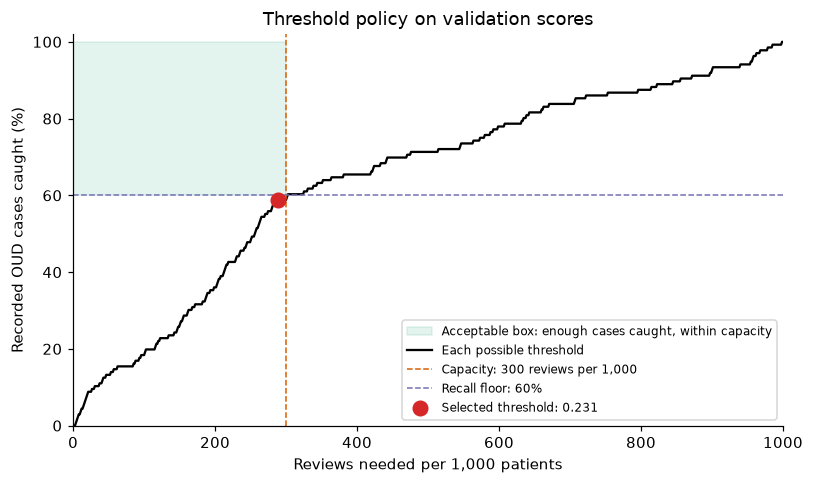

In [5]:
from utils import select_threshold, plot_threshold_policy, wilson_interval

MIN_RECALL = 0.60            # catch at least 60% of recorded OD cases
MAX_ALERTS_PER_1000 = 300    # review capacity

nb_pipe = Pipeline([("prep", preprocess), ("nb", BernoulliNB(alpha=1.0, fit_prior=True))])

# Validation scores: each training patient is scored by a model trained on the other 4/5 of the training set
val_scores = cross_val_predict(nb_pipe, X_train, y_train,
                               cv=StratifiedKFold(5, shuffle=True, random_state=0),
                               method="predict_proba")[:, 1]

choice = select_threshold(y_train, val_scores, MIN_RECALL, MAX_ALERTS_PER_1000)
threshold = choice["threshold"]          # FROZEN for this cohort-prior model (section 4.2 re-runs the rule for the 5% prior)
sel, tbl_thr = choice["selected"], choice["table"]

rec_ci = wilson_interval(sel["TP"], sel["TP"] + sel["FN"])
needed = tbl_thr.loc[tbl_thr["recall"] >= MIN_RECALL, "alerts_per_1000"].min()

print(choice["rule"])
print(f"\nSelected threshold (frozen): {threshold:.3f}")
print(f"Validation: catches {int(sel['TP'])} of {int(sel['TP'] + sel['FN'])} recorded OD cases "
      f"(recall {sel['recall']:.1%}, 95% CI {rec_ci[0]:.0%} to {rec_ci[1]:.0%}), "
      f"precision {sel['precision']:.1%}, {sel['alerts_per_1000']:.0f} reviews per 1,000")
print(f"To reach {MIN_RECALL:.0%} recall, the clinic would need about {needed:.0f} reviews per 1,000")

plot_threshold_policy(choice, MIN_RECALL, MAX_ALERTS_PER_1000)
plt.tight_layout(); plt.show()

**What happened?**
- **No threshold meets both conditions.** Within 300 reviews per 1,000, the best we can do is catch about **59%** of recorded OD cases. Reaching 60% would need about **303 reviews per 1,000**. We miss the target by 2 cases in the validation data (80 caught, 82 needed)
- **Rule 4 applies:** we do not quietly bend the rule. We report it, then use the fallback we declared in advance: **review capacity is a hard limit** (a clinic cannot review more patients than its staff can see), so we catch as many cases as capacity allows
- **Result:** threshold **0.231** (about 23%), frozen for this cohort-prior model. Section 4.2 re-runs the rule for the 5% prior. On validation it catches 80 of 136 recorded OD cases (59%, 95% interval 50% to 67%) with 289 reviews per 1,000
- **For the clinical team, this is a real decision:** accept about 59% recall, add a little review capacity, or improve the model. Section 12 discusses the last option

### 3.2. Step 2: evaluate once on the test set
The threshold is now frozen. We train on all training patients and open the test set for the first time.

--- Naive Bayes (all 20 features) ---
ROC AUC: 0.711  (95% CI 0.62 to 0.80)
PR AUC:  0.353  (no-skill baseline = 0.180)
At threshold 0.231 -> precision 0.418, recall 0.733

--- Baseline: Low_inc finding alone ---
ROC AUC: 0.745
PR AUC:  0.340  (no-skill baseline = 0.180)


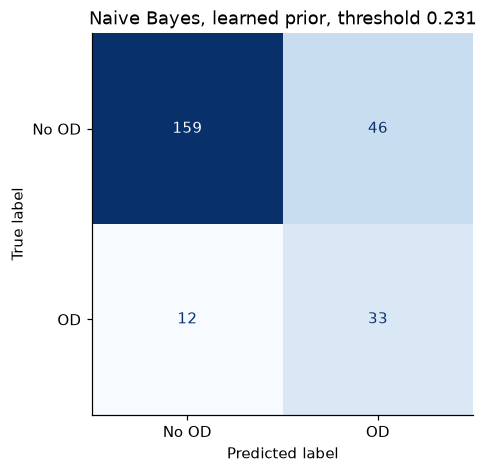

In [6]:
# Build the pipeline:
# alpha=1.0 applies Laplace smoothing so unseen/rare feature combinations never get probability exactly 0
# fit_prior=True learns the OD prior directly from the training data, about 18% in this cohort
nb_pipe = Pipeline([
    ("prep", preprocess),
    ("nb", BernoulliNB(alpha=1.0, fit_prior=True))
])

# Train the complete preprocessing + Naive Bayes pipeline
nb_pipe.fit(X_train, y_train)

# Predicted probability of OD for each patient
y_proba = nb_pipe.predict_proba(X_test)[:, 1]

# Use the threshold frozen in section 3.1 by the policy rule (not the 0.5 default)
y_pred = (y_proba >= threshold).astype(int)


# Bootstrap the test patients 2,000 times to estimate a 95% confidence interval for a metric
def boot_ci(y_true, score, metric, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    score = np.asarray(score)
    out = []

    for _ in range(n):
        # Sample patients with replacement, keeping the same sample size
        i = rng.integers(0, len(y_true), len(y_true))

        # ROC AUC requires both OD and No OD patients in the resampled data
        if 0 < y_true[i].sum() < len(i):
            out.append(metric(y_true[i], score[i]))

    # Keep the central 95% of the bootstrap results
    return np.percentile(out, [2.5, 97.5])


# Ranking metrics:
# ROC AUC asks how well the model ranks OD patients above No OD patients
# PR AUC focuses more directly on performance for the positive OD class
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

# 95% bootstrap confidence interval for ROC AUC
lo, hi = boot_ci(y_test, y_proba, roc_auc_score)

print("--- Naive Bayes (all 20 features) ---")
print(f"ROC AUC: {roc_auc:.3f}  (95% CI {lo:.2f} to {hi:.2f})")
print(f"PR AUC:  {pr_auc:.3f}  (no-skill baseline = {y_test.mean():.3f})")
print(
    f"At threshold {threshold:.3f} -> "
    f"precision {precision_score(y_test, y_pred):.3f}, "
    f"recall {recall_score(y_test, y_pred):.3f}"
)

# One-feature baseline:
# Use the binary Low_inc finding itself as a score, without fitting another model
# This asks whether that single yes/no variable ranks OD patients better than the full model
low_inc_score = X_test["Low_inc"]

roc_auc_lowinc = roc_auc_score(y_test, low_inc_score)
pr_auc_lowinc = average_precision_score(y_test, low_inc_score)

print("\n--- Baseline: Low_inc finding alone ---")
print(f"ROC AUC: {roc_auc_lowinc:.3f}")
print(f"PR AUC:  {pr_auc_lowinc:.3f}  (no-skill baseline = {y_test.mean():.3f})")


# Confusion matrix:
# Compare actual outcomes with predictions at our policy threshold
# It shows true negatives, false positives, false negatives and true positives
fig, ax = plt.subplots(figsize=(4.5, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    ax=ax,
    cmap="Blues",
    colorbar=False,
    display_labels=["No OD", "OD"]
)

ax.set_title(f"Naive Bayes, learned prior, threshold {threshold:.3f}")
plt.show()

**Critical reading**

- The full 20-feature model does **not clearly outperform** the single `Low_inc` finding. `Low_inc` does slightly better on ROC AUC (0.745 vs 0.711), while the full model does slightly better on PR AUC (0.353 vs 0.340). The other 19 features add little clear value on this test split. We check this more reliably with cross-validation in section 9
- Both PR AUC scores exceed the **0.18 no-skill baseline**, so both contain useful signal. Much of the model's predictive power appears to come from income alone
- At our policy threshold of **0.231**, the model catches **33 of 45 patients with OD (73%, 95% interval 59% to 84%)** and misses 12. It flags 79 patients, including 46 false alarms, so **42% of flagged patients have OD**
- **Validation said 59% recall, the test says 73%.** With only 45 cases in the test set, a few patients more or less move recall a lot. This is why we report intervals, and why the 60% floor is a target, not a guarantee
- **Workload:** 79 flags out of 250 is about **316 per 1,000**, slightly above capacity on this test split, even though validation was within it. Same lesson: small samples wobble

## 4. The prior $P(OD=1)$: the key Bayesian lesson

Our 1,000 patients are not a typical clinic: **18.1% have OD**. Research on the population where we would use the model puts the rate at about **5%** (the external estimate from the previous exercise, [source](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC2785002/)). That exercise describes it for the US population, so a real deployment needs the rate for its own patients, for example those receiving opioid prescriptions. The problem is the base rate, not the sample size: more patients from the same cohort would still show about 18%. Small-sample noise in the likelihoods is a separate issue (section 6).

Bayes' theorem lets us split the work:
- **The cohort tells us how findings relate to OD** (the likelihoods)
- **External research tells us how common OD is where the model will be used** (the prior)

In `BernoulliNB`:
- `fit_prior=True` (default): the prior is the class balance in the training data (18.1%). This assumes the clinic looks like the cohort
- `fit_prior=False, class_prior=[0.95, 0.05]`: the prior is the external 5%. This is our deployment prior

⚠️ **Assumption:** only the base rate differs. Sensitivities and false-positive rates are assumed to carry over to the 5% population. This notebook cannot check that. It needs validation data from that population

From here on, the 5% model is our main model. We use the cohort's 18% only to compare (this section and section 7), to calibrate against cohort outcomes (section 8.1) and to compare model families (section 9)

In [7]:
nb_model = nb_pipe.named_steps["nb"]
print(f"Learned prior P(OD=1): {np.exp(nb_model.class_log_prior_[1]):.4f}  (= training prevalence {y_train.mean():.4f})")

nb_external_prior = Pipeline([("prep", preprocess),
                              ("nb", BernoulliNB(alpha=1.0, fit_prior=False, class_prior=[0.95, 0.05]))])
nb_external_prior.fit(X_train, y_train)
ext_proba = nb_external_prior.predict_proba(X_test)[:, 1]
ext_pred = (ext_proba >= threshold).astype(int)

print("\n--- Ranking metrics (unchanged by the prior) ---")
print(f"ROC AUC  learned: {roc_auc_score(y_test, y_proba):.3f} | 5% prior: {roc_auc_score(y_test, ext_proba):.3f}")
print(f"PR AUC   learned: {average_precision_score(y_test, y_proba):.3f} | 5% prior: {average_precision_score(y_test, ext_proba):.3f}")

print(f"\n--- At threshold {threshold:.3f} (changed by the prior) ---")
for name, pred in [("Learned prior", y_pred), ("5% prior", ext_pred)]:
    tp = int(((pred == 1) & (y_test == 1)).sum()); fp = int(((pred == 1) & (y_test == 0)).sum())
    print(f"{name:14s}: flagged {pred.sum():3d} patients | true positives {tp:2d} | false positives {fp:2d} | "
          f"precision {precision_score(y_test, pred, zero_division=0):.3f} | recall {recall_score(y_test, pred):.3f}")

Learned prior P(OD=1): 0.1813  (= training prevalence 0.1813)

--- Ranking metrics (unchanged by the prior) ---
ROC AUC  learned: 0.711 | 5% prior: 0.711
PR AUC   learned: 0.353 | 5% prior: 0.353

--- At threshold 0.231 (changed by the prior) ---
Learned prior : flagged  79 patients | true positives 33 | false positives 46 | precision 0.418 | recall 0.733
5% prior      : flagged  22 patients | true positives  8 | false positives 14 | precision 0.364 | recall 0.178


### 4.1. What happened?

- **Ranking did not change**: changing only the prior changes every patient's starting risk, but the evidence from their features stays the same. Their predicted probabilities move, but their order does not. ROC AUC (0.711) and PR AUC (0.353) therefore stay the same
- **Decisions changed at the same 0.231 threshold**: the learned prior flags 79 patients, with 33 true positives and 46 false positives (precision 0.418, recall 0.733). The 5% prior flags 22 patients, with 8 true positives and 14 false positives (precision 0.364, recall 0.178); it misses 37 of 45 OD cases
- **Probability levels changed**: the 5% prior lowers all predicted risks because every patient starts from a lower baseline risk. A deployment prior must match the population, and calibration still needs checking

### 4.2. The prior changed, so re-run the threshold policy

Our threshold (**0.231**) was chosen in section 3.1 for the model with the learned **18%** prior. With a 5% prior every probability is lower, so the same 0.231 now flags only 22 patients instead of 79, and recall drops from 73% to 18%. The number 0.231 no longer means what it meant.

We should not guess a new number. We re-run **the same policy rule** from section 3.1 (catch at least 60% of cases, at most 300 reviews per 1,000, then highest precision) on validation scores from the 5% prior model.

One more change: the 300-review limit is about the **clinic's** patients. So we count reviews and precision as if 1,000 patients came from a 5% clinic. Recall and false-positive rate still come from our training patients

In [8]:
from utils import threshold_table

P_TARGET = 0.05    # external prior: OD prevalence in the target population

def select_threshold_at(y_true, score, prevalence, min_recall, max_alerts_per_1000):
    # Same policy rule as section 3.1, but reviews and precision are computed for a clinic with this prevalence
    # Recall and false-positive rate come from the validation scores; prevalence sets how many of 1,000 patients have OD
    tbl = threshold_table(y_true, score)
    fpr = tbl["FP"] / (np.asarray(y_true) == 0).sum()
    flagged_od = prevalence * tbl["recall"]
    flagged_all = flagged_od + (1 - prevalence) * fpr
    tbl["alerts_per_1000"] = 1000 * flagged_all
    tbl["precision"] = (flagged_od / flagged_all.where(flagged_all > 0)).fillna(0)
    within_capacity = tbl["alerts_per_1000"] <= max_alerts_per_1000
    feasible = tbl[within_capacity & (tbl["recall"] >= min_recall)]
    if not feasible.empty:
        best = feasible.sort_values(["precision", "threshold"], ascending=[False, False]).iloc[0]
        rule = "Primary rule met: recall floor and capacity both satisfied, highest precision"
    else:
        best = tbl[within_capacity].sort_values(["recall", "precision", "threshold"], ascending=False).iloc[0]
        rule = "Primary rule NOT feasible: fallback, stay within capacity and catch as many cases as possible"
    return best, rule

# Validation scores for the 5% model, from the training patients only
val_scores_ext = cross_val_predict(nb_external_prior, X_train, y_train,
                                   cv=StratifiedKFold(5, shuffle=True, random_state=0),
                                   method="predict_proba")[:, 1]
best_ext, rule_ext = select_threshold_at(y_train, val_scores_ext, P_TARGET, MIN_RECALL, MAX_ALERTS_PER_1000)
threshold_ext = float(best_ext["threshold"])
print(rule_ext)
print(f"Selected threshold for the 5% model: {threshold_ext:.3f}")
print(f"Validation, projected to a 5% clinic: recall {best_ext['recall']:.1%}, "
      f"{best_ext['alerts_per_1000']:.0f} reviews per 1,000, {best_ext['precision']:.1%} of flags are OD")

# Apply each model's own threshold to the same test patients
ext_pred_rerun = (ext_proba >= threshold_ext).astype(int)

summary_prior = pd.DataFrame({
    "Learned 18% prior": {"threshold": threshold, "patients flagged": y_pred.sum(),
                          "OD cases caught": int(((y_pred == 1) & (y_test == 1)).sum()),
                          "recall": recall_score(y_test, y_pred), "precision": precision_score(y_test, y_pred)},
    "5% prior, rule at 5% prevalence": {"threshold": threshold_ext, "patients flagged": ext_pred_rerun.sum(),
                                        "OD cases caught": int(((ext_pred_rerun == 1) & (y_test == 1)).sum()),
                                        "recall": recall_score(y_test, ext_pred_rerun), "precision": precision_score(y_test, ext_pred_rerun)},
}).T
display(summary_prior.style.format({"threshold": "{:.3f}", "patients flagged": "{:.0f}", "OD cases caught": "{:.0f}",
                                    "recall": "{:.1%}", "precision": "{:.1%}"})
        .set_caption("Test set (250 patients, 18% OD): the test set has the cohort's prevalence, not 5%"))
both = int(((y_pred == 1) & (ext_pred_rerun == 1)).sum())
print(f"Patients flagged by both models: {both} (cohort prior flags {y_pred.sum()}, 5% prior flags {ext_pred_rerun.sum()})")

Primary rule met: recall floor and capacity both satisfied, highest precision
Selected threshold for the 5% model: 0.060
Validation, projected to a 5% clinic: recall 60.3%, 254 reviews per 1,000, 11.8% of flags are OD


,threshold,patients flagged,OD cases caught,recall,precision
Learned 18% prior,0.231,79,33,73.3%,41.8%
"5% prior, rule at 5% prevalence",0.060,85,33,73.3%,38.8%


Patients flagged by both models: 79 (cohort prior flags 79, 5% prior flags 85)


**What this shows**
- The policy picked a much lower number for the 5% model (**0.060** instead of 0.231). On the test set it flags 85 patients instead of 79. All 79 patients flagged by the cohort model are among them, and the 33 cases caught are the same
- Two things moved the number. **The prior** lowers every probability, so the threshold must fall. **The prevalence** changes the workload: in a 5% clinic, catching 60% of cases needs about 254 reviews per 1,000, against 289 in our cohort, because there are fewer cases to flag. So the rule can be met at 5% (60.3% recall within 300 reviews) where it could not at 18% (section 3.1)
- **The threshold number only makes sense together with the model, the prior and the prevalence it was set for.** Move a model to a new setting: re-run the rule, never copy the number
- The test patients still have 18% OD, so their precision overstates what a 5% clinic would see. Section 10 projects it to 5%
- One honest caveat: we set 0.060 from training patients re-weighted to 5%. A real clinic would re-run the rule on validation data **from its own population** (section 10.3)

### 4.3. How much does the prior move one patient's risk?
We take three test patients and ask the model for their risk while changing **only** the prior, from 1% to 50%. Their findings stay the same. This is the clinical idea of **pre-test probability**: the same findings mean different things in a general practice, a pain clinic or an addiction service.

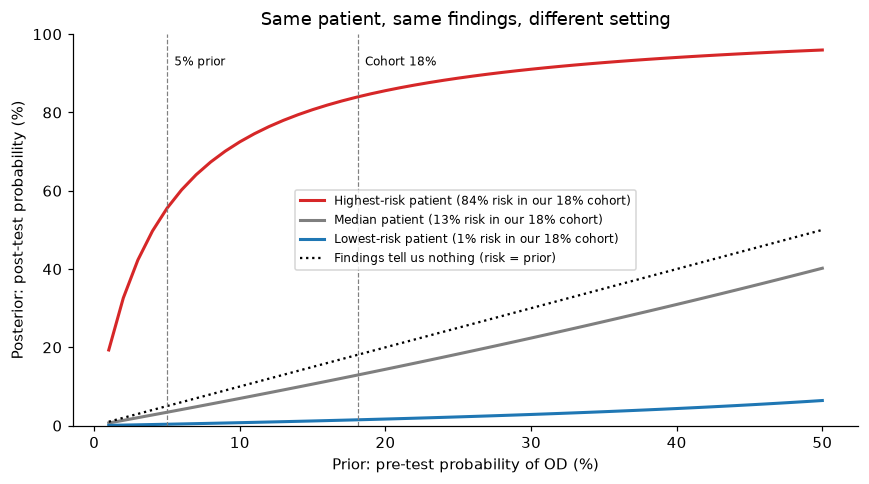

In [9]:
# Three test patients, picked by their risk under the learned 18% prior
picks = {"Highest-risk patient": np.argmax(y_proba),
         "Median patient": np.argsort(y_proba)[len(y_proba) // 2],
         "Lowest-risk patient": np.argmin(y_proba)}

prep = nb_pipe.named_steps["prep"]
Xtr_bin, Xte_bin = prep.transform(X_train), prep.transform(X_test)

# Refit the same model with different priors (likelihoods stay identical, only the starting point changes)
priors = np.linspace(0.01, 0.50, 50)
risk = {label: [] for label in picks}
for p in priors:
    m_p = BernoulliNB(alpha=1.0, fit_prior=False, class_prior=[1 - p, p]).fit(Xtr_bin, y_train)
    proba_p = m_p.predict_proba(Xte_bin)[:, 1]
    for label, i in picks.items():
        risk[label].append(proba_p[i])

fig, ax = plt.subplots(figsize=(8, 4.5))
for (label, i), c in zip(picks.items(), ["#d62728", "#7f7f7f", "#1f77b4"]):
    ax.plot(priors * 100, np.array(risk[label]) * 100, c=c, lw=2,
            label=f"{label} ({y_proba[i]:.0%} risk in our 18% cohort)")
ax.plot(priors * 100, priors * 100, "k:", label="Findings tell us nothing (risk = prior)")
for p, txt in [(5, "5% prior"), (18.1, "Cohort 18%")]:
    ax.axvline(p, ls="--", c="grey", lw=.8); ax.text(p + .5, 92, txt, fontsize=8)
ax.set(xlabel="Prior: pre-test probability of OD (%)", ylabel="Posterior: post-test probability (%)",
       title="Same patient, same findings, different setting", ylim=(0, 100)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**How to read it**
- Each coloured line is one patient. Only the starting point (the prior) changes along the bottom axis
- On the dotted line, the patient's findings would tell us nothing: the risk would simply equal the prior
- **Above** the dotted line: the findings push the risk up. **Below** it: they push the risk down
- The highest-risk patient is about a coin flip in a 5% setting but very likely to have OD in our 18% cohort. Same findings, different setting, very different conclusion

### 4.4. Fagan nomogram: the same update on paper

<img src="media/fagan.png" alt="Fagan nomogram" width="640">

*Join the pre-test probability (left) to the likelihood ratio (middle) with a ruler, and read the post-test probability (right). Example: an 18% prior and the low-income LR of 2.6 give about 37%, as in section 1.4*


## 5. Inside the model: what it learned (global view)

The likelihoods $P(x=1 \mid OD)$ do **not** depend on the prior, so both models share this table. We show **all** features, including those pointing *away* from OD.

How to read it, in clinical language:
- `P(x=1|OD=1)`: sensitivity of the finding, e.g. 61% of patients with OD are low income
- `P(x=1|OD=0)`: 1 − specificity, e.g. 24% of patients without OD are low income
- `LR+`: individual LR of a **present** finding, how much it multiplies the odds of OD
- `LR-`: individual LR of an **absent** finding, how much it multiplies the odds of OD (BernoulliNB uses this too)
- `OR` (odds ratio) = LR+ ÷ LR−: how many times higher the odds of OD are when the finding is **present** than when it is **absent**. We rank the table by it. Careful: a common finding can rank high just because its *absence* is informative. `rx_ds` has LR+ of only 1.09 but ranks 3rd, because having no opioid supply at all lowers the odds (LR− 0.77)

⚠️ Read LR+ in the right direction. "Low income is 2.6× more common among patients with OD" is **not** "low-income patients are 2.6× more likely to develop OD". Swapping the two is the classic *inverse probability fallacy*.

In [10]:
feat_names = np.array([n.replace("binary__", "").replace("bin_rx__", "") for n in
                       nb_pipe.named_steps["prep"].get_feature_names_out()])
p1 = np.exp(nb_model.feature_log_prob_[1]); p0 = np.exp(nb_model.feature_log_prob_[0])

# Short labels based on Data/CaseStudy_training_data.xlsx, sheet "data dictionary"
description_by_feature = {
    "Low_inc": "Low income",
    "SURG": "Major surgery",
    "rx_ds": "Opioid supply",
    "A": "Infectious diseases (group A)",
    "B": "Infectious diseases (group B)",
    "C": "Malignant neoplasm",
    "D": "Benign neoplasm",
    "E": "Endocrine conditions",
    "F": "Mental health",
    "H": "Ear conditions",
    "I": "Circulatory system",
    "J": "Respiratory system",
    "K": "Digestive system",
    "L": "Skin conditions",
    "M": "Musculoskeletal system",
    "N": "Urinary system",
    "R": "Other symptoms",
    "S": "Injuries",
    "T": "Burns, toxicity",
    "V": "External trauma",
}

tbl = pd.DataFrame({
    "feature": feat_names,
    "description": [description_by_feature[name] for name in feat_names],
    "P(x=1|OD=1)": p1, "P(x=1|OD=0)": p0,
    "LR+": p1 / p0, "LR-": (1 - p1) / (1 - p0),
}).assign(OR=lambda d: d["LR+"] / d["LR-"]).sort_values("OR", ascending=False)

display(tbl.style.hide(axis="index").format(precision=3)
        .background_gradient(subset=["OR"], cmap="RdBu_r", gmap=np.log(tbl["OR"]), vmin=-1.7, vmax=1.7))  # red = toward OD, blue = away


feature,description,P(x=1|OD=1),P(x=1|OD=0),LR+,LR-,OR
Low_inc,Low income,0.609,0.237,2.568,0.513,5.008
V,External trauma,0.094,0.057,1.658,0.960,1.726
rx_ds,Opioid supply,0.790,0.727,1.086,0.771,1.409
F,Mental health,0.565,0.521,1.085,0.908,1.195
E,Endocrine conditions,0.609,0.571,1.065,0.913,1.167
SURG,Major surgery,0.442,0.407,1.085,0.942,1.152
J,Respiratory system,0.522,0.502,1.040,0.960,1.084
N,Urinary system,0.471,0.451,1.044,0.964,1.083
A,Infectious diseases (group A),0.362,0.352,1.029,0.984,1.045
K,Digestive system,0.529,0.528,1.003,0.997,1.006


### Clinical insights: What do these findings tell us?

- **Income outweighs medical history:** Low income (`Low_inc`, OR = 5.0) is a much stronger predictor than mental health conditions (`F`, OR = 1.20) or surgery (`SURG`, OR = 1.15). **Is the model learning clinical risk or socioeconomic patterns?**

- **Opioid exposure is surprisingly weak:** Prescription supply (`rx_ds`, OR = 1.41) contributes little, despite its clinical relevance. But we reduced it to "any supply", losing information about duration. **Are we measuring the right things?**

- **Some clinical associations seem backwards:** Symptoms (`R`, OR = 0.42), burns/toxic conditions (`T`, OR = 0.46), and musculoskeletal conditions (`M`, OR = 0.60) point away from OD. **Why?** Coding practices or synthetic data patterns may explain this. These conditions are not necessarily protective

- **Don't overinterpret apparent signals:** External trauma (`V`, OR = 1.73) looks relevant, but is relatively rare, and its estimated effect is uncertain. **A high odds ratio alone is not strong evidence**

**Clinical takeaway:** Naive Bayes relies heavily on income, and the clinical findings add little **to this model**. Section 9 tests whether other models extract more from the same findings. We need better clinical features and stronger validation before this supports care decisions

### Which features matter most?

- **Left chart:** How common is each feature among patients with and without OD? Greater separation means stronger evidence
- **Right chart:** How strongly is each feature associated with OD? Odds ratio (OR) > 1 means higher odds, < 1 means lower odds, and 1 means no association

*(These are associations, not causal effects)*

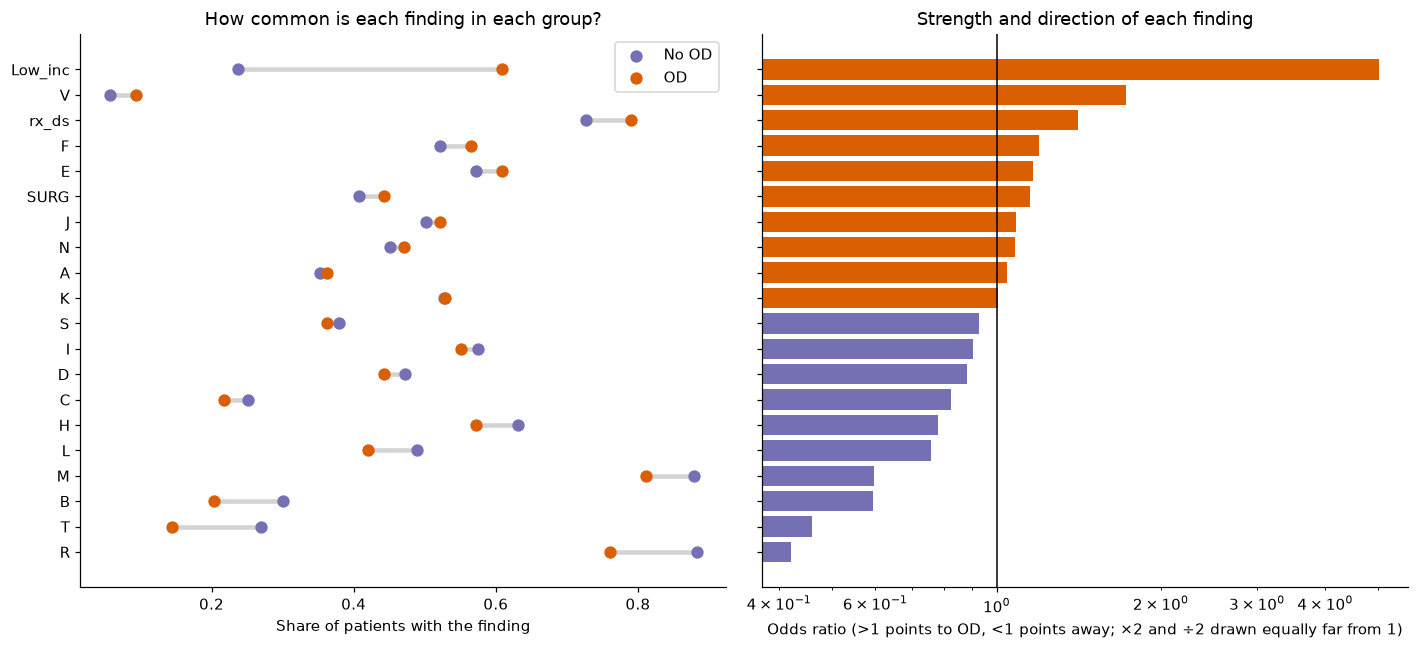

In [11]:
t = tbl.sort_values("OR")
fig, ax = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
yy = np.arange(len(t))
ax[0].hlines(yy, t["P(x=1|OD=0)"], t["P(x=1|OD=1)"], color="lightgrey", lw=3)
ax[0].scatter(t["P(x=1|OD=0)"], yy, color=C_NO, s=50, label="No OD", zorder=3)
ax[0].scatter(t["P(x=1|OD=1)"], yy, color=C_OD, s=50, label="OD", zorder=3)
ax[0].set(yticks=yy, yticklabels=t["feature"], xlabel="Share of patients with the finding",
          title="How common is each finding in each group?"); ax[0].legend()
colors = [C_OD if v > 1 else C_NO for v in t["OR"]]
ax[1].barh(yy, t["OR"], color=colors); ax[1].axvline(1, c="k", lw=1)
ax[1].set_xscale("log"); ax[1].set(xlabel="Odds ratio (>1 points to OD, <1 points away; ×2 and ÷2 drawn equally far from 1)",
                                   title="Strength and direction of each finding")
plt.tight_layout(); plt.show()

**What the charts show**
- **Left:** each line joins the share of patients with the finding among those without OD (purple) and with OD (orange). A longer line means a bigger difference
- **Right:** bars far from 1 are stronger signals. After income, the clearest ones point **away** from OD: `R`, `T`, `M` and `B`. Whether they are reliable is the question of the next section


## 6. How sure are we? Laplace smoothing and Bayesian uncertainty

**The problem:** What if a feature is very rare or never appears in our training data? Should the model conclude it is impossible?

### 6.1. Laplace smoothing: Avoid being too certain

`BernoulliNB(alpha=1)` adds two imaginary observations for each feature, within each patient group: **one with the feature and one without it**

For example, external trauma (`V`) appears in **12 of 136 patients with OD**:

- **Without smoothing:** 12/136 = 8.8%
- **With smoothing:** (12+1)/(136+2) = **9.4%**

This prevents the model from assigning probabilities of exactly 0% or 100% just because of limited observations

### 6.2. Why is this Bayesian?

Those imaginary observations represent a **prior belief**: before seeing the data, we do not favor any particular percentage

This is called a **Beta(1,1) prior**. The observed data then update that belief

*Note: This prior concerns how common each feature is, not the overall 18% prior probability of OD*

### 6.3. But how confident are we in the result?

**A single estimated percentage does not tell us how reliable it is**

- A feature observed in hundreds of patients gives us more confidence
- A rare feature observed in only a few patients gives us less confidence

Bayesian analysis allows us to express this uncertainty as a **range of plausible values**, rather than trusting one number

**Clinical question:** External trauma (`V`) has a positive likelihood ratio (LR+) of approximately 1.7. Is this reliable evidence of higher OD odds, or could it simply reflect our limited data?

That's what we investigate next.

Training counts | V: 12/136 OD patients vs 34/614 non-OD
                | Low_inc: 83/136 OD patients vs 145/614 non-OD


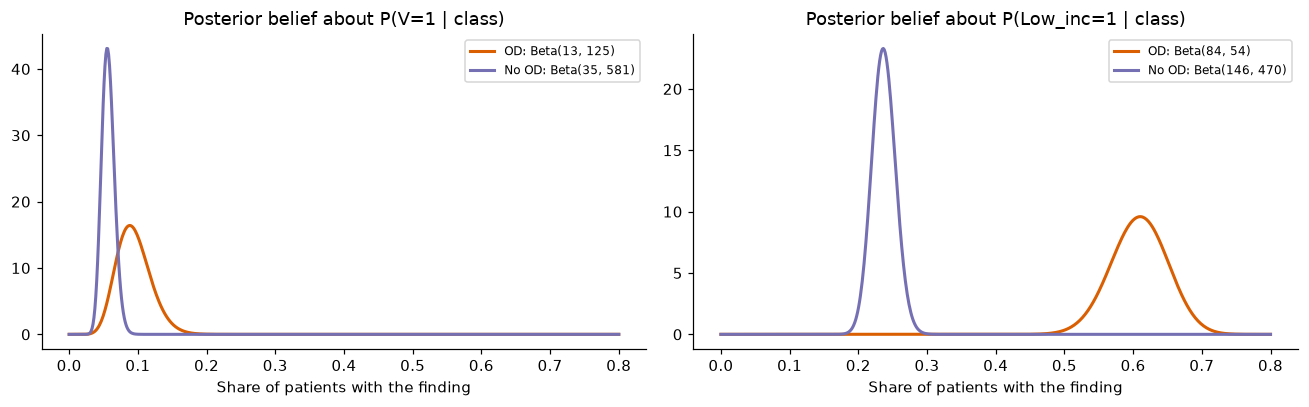

In [12]:
from scipy import stats
nb_c = nb_model.class_count_; fc = nb_model.feature_count_
j_v, j_li = list(feat_names).index("V"), list(feat_names).index("Low_inc")
print(f"Training counts | V: {fc[1, j_v]:.0f}/{nb_c[1]:.0f} OD patients vs {fc[0, j_v]:.0f}/{nb_c[0]:.0f} non-OD")
print(f"                | Low_inc: {fc[1, j_li]:.0f}/{nb_c[1]:.0f} OD patients vs {fc[0, j_li]:.0f}/{nb_c[0]:.0f} non-OD")

xs = np.linspace(0, 0.8, 600)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, j, name in [(ax[0], j_v, "V"), (ax[1], j_li, "Low_inc")]:
    for c, col, lab in [(1, C_OD, "OD"), (0, C_NO, "No OD")]:
        k, n = fc[c, j], nb_c[c]
        a.plot(xs, stats.beta(k + 1, n - k + 1).pdf(xs), color=col, lw=2, label=f"{lab}: Beta({k+1:.0f}, {n-k+1:.0f})")
    a.set(title=f"Posterior belief about P({name}=1 | class)", xlabel="Share of patients with the finding"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

The curves are the model's *belief* about each percentage. Where the two curves overlap, the data cannot tell the groups apart with confidence. Next we turn these beliefs into a **95% credible interval for every LR+** by simulation (draw both percentages from their Beta curves, divide, repeat 20,000 times).

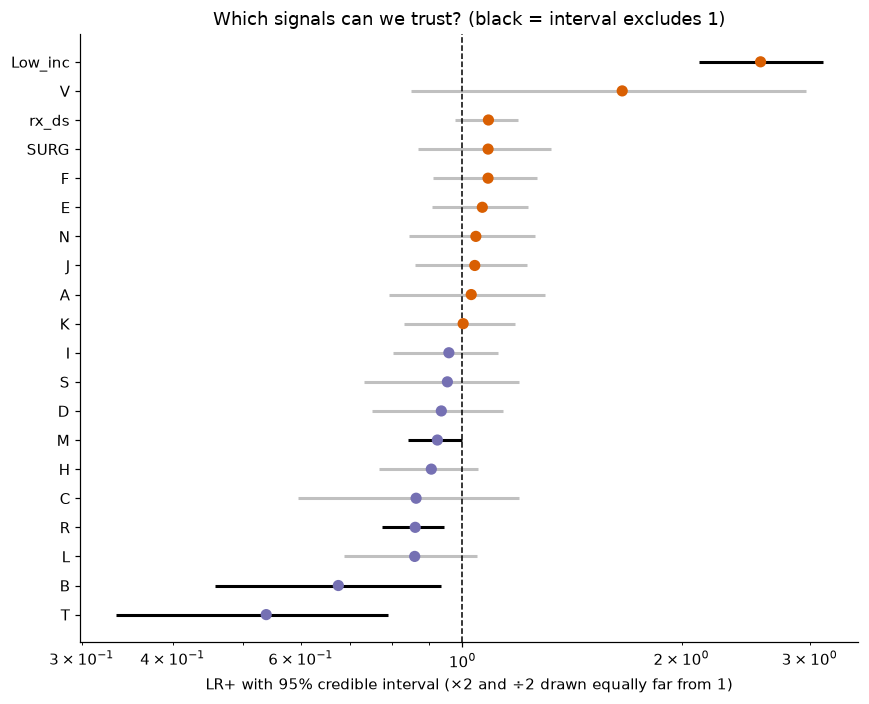

feature,LR+,low,high,P(LR+ > 1)
Low_inc,2.57,2.11,3.13,1.00
V,1.66,0.85,2.96,0.93
rx_ds,1.09,0.98,1.19,0.94
SURG,1.08,0.87,1.32,0.77
F,1.08,0.91,1.27,0.83
E,1.07,0.91,1.23,0.80
N,1.04,0.85,1.26,0.66
J,1.04,0.86,1.23,0.67
A,1.03,0.79,1.30,0.59
K,1.00,0.83,1.18,0.52


In [13]:
rng = np.random.default_rng(0); S = 20_000
rows = []
for j, name in enumerate(feat_names):
    d1 = rng.beta(fc[1, j] + 1, nb_c[1] - fc[1, j] + 1, S)
    d0 = rng.beta(fc[0, j] + 1, nb_c[0] - fc[0, j] + 1, S)
    lr = d1 / d0
    rows.append({"feature": name, "LR+": p1[j] / p0[j], "low": np.percentile(lr, 2.5),
                 "high": np.percentile(lr, 97.5), "P(LR+ > 1)": (lr > 1).mean()})
cred = pd.DataFrame(rows).sort_values("LR+")

fig, ax = plt.subplots(figsize=(8, 6.5))
yy = np.arange(len(cred))
sure = (cred["low"] > 1) | (cred["high"] < 1)
ax.hlines(yy, cred["low"], cred["high"], color=np.where(sure, "k", "silver"), lw=2)
ax.scatter(cred["LR+"], yy, color=np.where(cred["LR+"] > 1, C_OD, C_NO), zorder=3, s=40)
ax.axvline(1, c="k", ls="--", lw=1); ax.set_xscale("log")
ax.set(yticks=yy, yticklabels=cred["feature"], xlabel="LR+ with 95% credible interval (×2 and ÷2 drawn equally far from 1)",
       title="Which signals can we trust? (black = interval excludes 1)")
plt.tight_layout(); plt.show()
display(cred.sort_values("LR+", ascending=False).style.hide(axis="index").format(precision=2))

**Reading it for clinicians**
- Only a few intervals clearly exclude 1 (black lines). Those are the signals the data supports
- `V` has a wide interval: it rests on about a dozen patients with OD. Saying "V makes OD 1.7× more likely" overstates what we know. A fair statement is "we can't rule out that V carries no information"
- `P(LR+ > 1)` is the posterior probability that the finding points toward OD. A Bayesian answer to "how sure are we about the direction?"
- With 20 features, a few intervals will exclude 1 by chance. Treat single weak signals as hypotheses to test, not conclusions

## 7. One patient: from pre-test to post-test probability

We use **patient 20** to show exactly how Naive Bayes produces one predicted probability. We start with the external **5% prior** and later compare it with the learned **18.1% cohort prior**.

The patient's **findings/features** are the 20 recorded variables, including both present (`Value = 1`) and absent (`Value = 0`) findings. Each contributes an **individual likelihood ratio (LR)**. Absent findings contribute too ([scikit-learn guide](https://scikit-learn.org/stable/modules/naive_bayes.html)).

Multiplying all 20 individual LRs gives the **combined likelihood ratio (Bayes factor)**:

$$\text{Combined LR (BF)} = LR_1 \times LR_2 \times \cdots \times LR_{20} = 2.79$$

**2.79 is not the patient's predicted probability.** Here is the calculation the next code cell will verify.

### How does the 5% prior become a 12.79% posterior?

**Step 1. Convert the starting probability into odds**

$$\text{Prior odds} = \frac{0.05}{1-0.05} = \frac{0.05}{0.95} \approx 0.0526$$

**Step 2. Apply the combined evidence from all 20 findings/features**

$$
\underbrace{\text{Prior odds}}_{0.05/0.95}
\times
\underbrace{BF}_{2.79}
=
\underbrace{\text{Posterior odds}}_{0.147}
$$

**Step 3. Convert the updated odds back into the predicted probability**

$$P(OD=1 \mid X) = \frac{0.147}{1+0.147} \approx \boxed{12.79\%}$$

In the next code cell, `pre_odds` performs Step 1, `post_odds` performs Step 2, and `p_manual` performs Step 3. The value from `model.predict_proba(...)` is shown alongside it. **`Match: True`** confirms our explicit calculation reproduces scikit-learn's prediction.

The tables after the printed result show the individual LRs behind the **2.79**. The following chart shows how those LRs update the probability, one step at a time.

In [14]:

test_i = 20  # Change to explore other patients
model = nb_external_prior  # Switch to nb_pipe for the learned ~18% prior
m = model.named_steps["nb"]
x = model.named_steps["prep"].transform(X_test)[test_i].astype(int)

# Feature probabilities learned from the training data
p_od = np.exp(m.feature_log_prob_[1])
p_no = np.exp(m.feature_log_prob_[0])
prior = np.exp(m.class_log_prior_[1])

# Individual likelihood ratios (LRs) for all 20 findings/features
# A present feature (1) uses LR+; an absent feature (0) uses LR-
lr = np.where(x == 1, p_od / p_no, (1 - p_od) / (1 - p_no))

# Combined LR (Bayes factor): multiply all 20 individual LRs
combined_lr = float(np.prod(lr))

# Reproduce the model's prediction in three steps:
# 1. Convert the prior probability to odds
pre_odds = prior / (1 - prior)

# 2. Multiply by the combined LR
post_odds = pre_odds * combined_lr

# 3. Convert the updated odds back to probability
p_manual = post_odds / (1 + post_odds)

# Verify against scikit-learn's prediction
p_sklearn = model.predict_proba(X_test.iloc[[test_i]])[0, 1]
assert np.isclose(p_manual, p_sklearn)

# Compare the same patient under the other prior
other_model = nb_pipe if model is nb_external_prior else nb_external_prior
other_nb = other_model.named_steps["nb"]

other_p_od = np.exp(other_nb.feature_log_prob_[1])
other_p_no = np.exp(other_nb.feature_log_prob_[0])

other_lr = np.where(
    x == 1,
    other_p_od / other_p_no,
    (1 - other_p_od) / (1 - other_p_no)
)

other_prior = np.exp(other_nb.class_log_prior_[1])
other_p = other_model.predict_proba(X_test.iloc[[test_i]])[0, 1]

likelihoods_unchanged = np.allclose(lr, other_lr)
assert likelihoods_unchanged

print(f"Patient {test_i} | Actual OD label: {y_test.iloc[test_i]}")
print(f"Starting probability (prior): {prior:.1%}")
print(f"Combined LR (Bayes factor, all 20 features): {combined_lr:.2f}")
print(
    f"Calculated step by step: {p_manual:.2%} | "
    f"scikit-learn: {p_sklearn:.2%} | "
    f"Match: {np.isclose(p_manual, p_sklearn)}"
)
print(f"Same patient under the other prior ({other_prior:.1%}): {other_p:.1%}")
print(f"Individual LRs identical across priors: {likelihoods_unchanged}")

# ONE calculation table: seven strongest features + remaining 13
# Keep 'local' sorted for compatibility with subsequent notebook cells
local = pd.DataFrame({
    "Finding/feature": feat_names,
    "Value": x,
    "Individual LR": lr
})
local = local.iloc[np.argsort(-np.abs(np.log(lr)))]

top_k = 7
top_indices = local.index.to_numpy()[:top_k]
remaining_indices = local.index.to_numpy()[top_k:]
remaining_lr = float(np.prod(lr[remaining_indices]))

calculation_rows = []
running_lr = 1.0

# Multiply the strongest individual LRs one at a time
for j in top_indices:
    running_lr *= lr[j]

    calculation_rows.append({
        "Finding/feature": feat_names[j],
        "Value": int(x[j]),
        "Individual LR": lr[j],
        "Combined LR": running_lr,
    })

# Include the remaining features as one grouped multiplication
assert np.isclose(running_lr * remaining_lr, combined_lr)

calculation_rows.append({
    "Finding/feature": f"Remaining {len(remaining_indices)} findings/features",
    "Value": "Grouped",
    "Individual LR": remaining_lr,
    "Combined LR": combined_lr,
})

calculation_table = pd.DataFrame(calculation_rows)

print("Multiply each individual LR by the result from the previous row.")
print("The final row includes all 20 features and gives the Bayes factor.")

display(
    calculation_table.style.hide(axis="index").format({
        "Individual LR": "{:.3f}",
        "Combined LR": "{:.3f}"
    })
)


Patient 20 | Actual OD label: 0
Starting probability (prior): 5.0%
Combined LR (Bayes factor, all 20 features): 2.79
Calculated step by step: 12.79% | scikit-learn: 12.79% | Match: True
Same patient under the other prior (18.1%): 38.2%
Individual LRs identical across priors: True
Multiply each individual LR by the result from the previous row.
The final row includes all 20 features and gives the Bayes factor.


Finding/feature,Value,Individual LR,Combined LR
Low_inc,1,2.568,2.568
T,0,1.170,3.006
L,1,0.860,2.586
R,1,0.862,2.228
H,0,1.160,2.585
C,1,0.864,2.233
B,0,1.139,2.544
Remaining 13 findings/features,Grouped,1.095,2.786


The **calculation table above** shows the seven strongest individually and groups the remaining 13. Its *Combined LR* column shows their running product, ending at **2.79**. The waterfall chart below uses the **same seven-plus-thirteen sequence**, but displays the changing **probability**, rather than the LR.

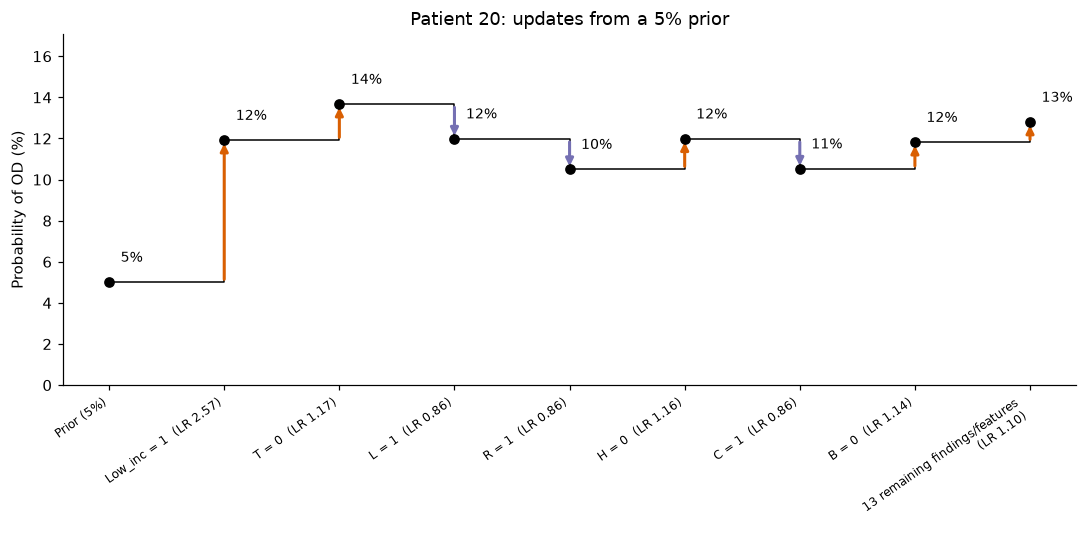

In [15]:
# Use the same seven findings and grouped remainder shown in the calculation table
labels = [f"Prior ({prior:.0%})"]
odds_steps = [pre_odds]
for j in top_indices:
    odds_steps.append(odds_steps[-1] * lr[j])
    labels.append(f"{feat_names[j]} = {x[j]}  (LR {lr[j]:.2f})")
odds_steps.append(odds_steps[-1] * remaining_lr)
labels.append(f"{len(remaining_indices)} remaining findings/features\n(LR {remaining_lr:.2f})")
probs = 100 * np.array(odds_steps) / (1 + np.array(odds_steps))
assert np.isclose(probs[-1] / 100, p_manual)

fig, ax = plt.subplots(figsize=(10, 5))
ax.step(range(len(probs)), probs, where="post", c="k", lw=1)
for i in range(1, len(probs)):
    up = probs[i] > probs[i-1]
    ax.annotate("", xy=(i, probs[i]), xytext=(i, probs[i-1]),
                arrowprops=dict(arrowstyle="-|>", color=C_OD if up else C_NO, lw=2))
ax.scatter(range(len(probs)), probs, c="k", zorder=3)
for i, p in enumerate(probs): ax.text(i + .1, p + 1, f"{p:.0f}%", fontsize=9)
ax.set_xticks(range(len(probs)), labels, rotation=35, ha="right", fontsize=8)
ax.set(ylabel="Probability of OD (%)", title=f"Patient {test_i}: updates from a {prior:.0%} prior",
       ylim=(0, max(probs) * 1.25))
plt.tight_layout(); plt.show()


### So what?

- **Low income dominates:** It alone raises predicted risk from 5% to 12%
- **Other features largely cancel each other out**, leaving a final prediction of 12.79%

> ⚠️ **A transparent calculation isn't necessarily a trustworthy clinical prediction**

### Same patient, different priors

| | Target population (external prior) | Our cohort (learned prior) |
|---|---:|---:|
| Starting probability | 5% | 18.1% |
| Patient's findings/features | Same 20 | Same 20 |
| Combined likelihood ratio (BF) | 2.79 | 2.79 |
| **Final predicted probability** | **12.79%** | **38.2%** |

**Imagine the same patient in two settings:**

- **Target population:** starts at 5%, so the model predicts **12.79%**
- **Our cohort:** starts at 18.1%, so the model would predict **38.2%**

**The patient has not changed.** Both use the same feature estimates learned from the same training data. Their individual LRs (and combined BF) are identical; only the starting probability changes

### So what? Why does the prior matter?

- A model's predicted risk depends on the **starting prevalence**, not just the patient's findings/features
- The cohort's own 18.1% would overstate this patient's risk about threefold for a 5% clinic (38.2% vs 12.79%). The external prior fixes the starting point; the findings still come from the cohort
- This assumes the **likelihoods transfer** to the target population. In a different hospital, feature patterns and LRs may differ too, so **changing the prior alone is not enough**; validation in the intended population is essential
- Correlated findings/features can also make Naive Bayes overcount evidence, even when the prior is appropriate

> **Same patient + same findings/features + different starting probability = different final probability. That's Bayesian updating in action!**

## 8. Is the "naive" assumption a problem here?

**The problem: Counting the same evidence twice**

Naive Bayes assumes features are independent within each patient group. But what if two medical conditions frequently occur together?

e.g., if `M` and `R` are strongly correlated among patients with OD. The model may treat them as **two independent pieces of evidence**, exaggerating their combined effect.

**Why does this matter?**

The model might predict a **30% probability of OD**, but only 15% actually have it. Its probabilities are then **poorly calibrated**, even if it ranks higher-risk patients reasonably well.

**Which prior are we using, and why?**

- **Correlation:** We examine relationships between features among patients with OD. Changing the overall OD prior from 18% to 5% does not change these relationships in our trained model
- **Calibration:** This check compares predicted risks with outcomes in our cohort, so it uses the model with the cohort's own **18% prior**. A 5% prior would predict too low against 18% outcomes by construction, so it would only re-learn the cohort's base rate. Checking the 5% prior needs data from the 5% population

**So what?** A model can rank patients reasonably well while giving misleading probabilities. We need to check both **feature correlations** and **whether predicted risks match actual outcomes**.

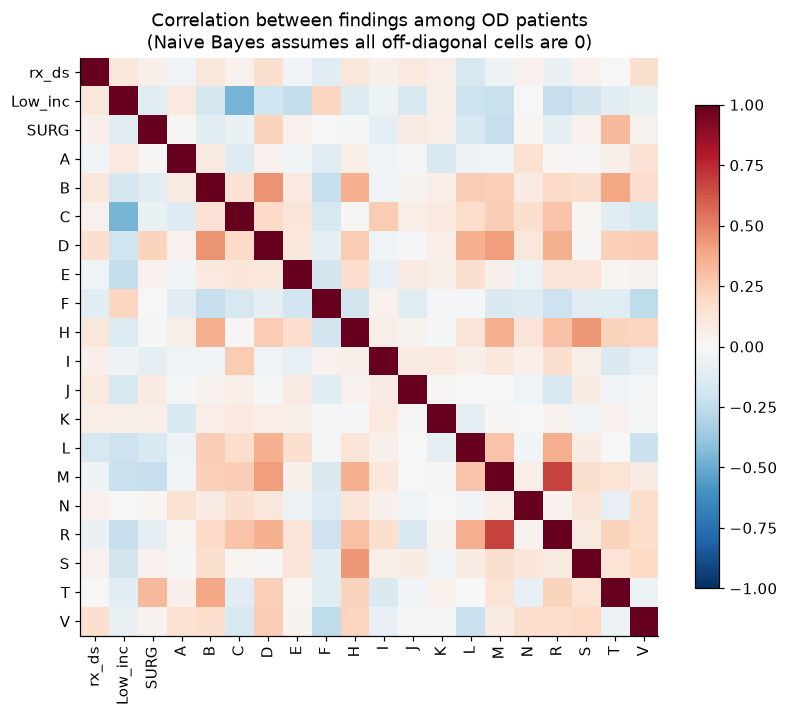

Strongest pairs:
 M        R    0.68
Low_inc  C    0.47
B        D    0.45
H        S    0.43
D        M    0.42

M and R: r = 0.68 among OD patients, 0.15 among No OD patients


In [16]:
Xtr_bin = pd.DataFrame(nb_pipe.named_steps["prep"].transform(X_train), columns=feat_names)
corr = Xtr_bin[y_train.values == 1].corr()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feat_names)), feat_names, rotation=90); ax.set_yticks(range(len(feat_names)), feat_names)
ax.set_title("Correlation between findings among OD patients\n(Naive Bayes assumes all off-diagonal cells are 0)")
plt.colorbar(im, ax=ax, shrink=.8); plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Strongest pairs:\n", pairs.abs().sort_values(ascending=False).head(5).round(2).to_string())
r_od = corr.loc["M", "R"]; r_no = Xtr_bin[y_train.values == 0].corr().loc["M", "R"]
print(f"\nM and R: r = {r_od:.2f} among OD patients, {r_no:.2f} among No OD patients")

### So what? Should we remove one of these features?

`M` and `R` are strongly correlated among patients with OD (**r ≈ 0.68**), and much less among patients without OD (r ≈ 0.15, printed above). Naive Bayes may count their overlapping evidence twice, producing exaggerated probabilities

**What should we do?**

- **Don't automatically remove either feature:** correlation alone doesn't prove harm
- **Optional exercise (question 7 in section 14):** compare the original model with versions removing `M`, `R` or both, using PR AUC (case finding) and Brier score (probability accuracy, defined below)
- **For now, we keep both features** and check whether the probabilities are reliable

### 8.1. Naive Bayes before vs after sigmoid calibration

If the model predicts a **30% probability of OD** for 100 patients, about 30 should actually have OD. If substantially fewer or more do, its probabilities are poorly calibrated.

For the method, see the [Responsible AI notebook, section 6: Recalibrating the Scores](../RAI/ML4HL_OD_RAI_toolbox.ipynb)

We compare the model in three steps:
1. Check raw Naive Bayes probabilities: are they too high or too low?
2. Apply the same sigmoid calibration method
3. Compare the probabilities before and after

This check uses nested cross-validation on the 750 training patients only. The test set stays closed. We use the learned **18% cohort prior**, not the external 5% prior, because we compare predictions with cohort outcomes.

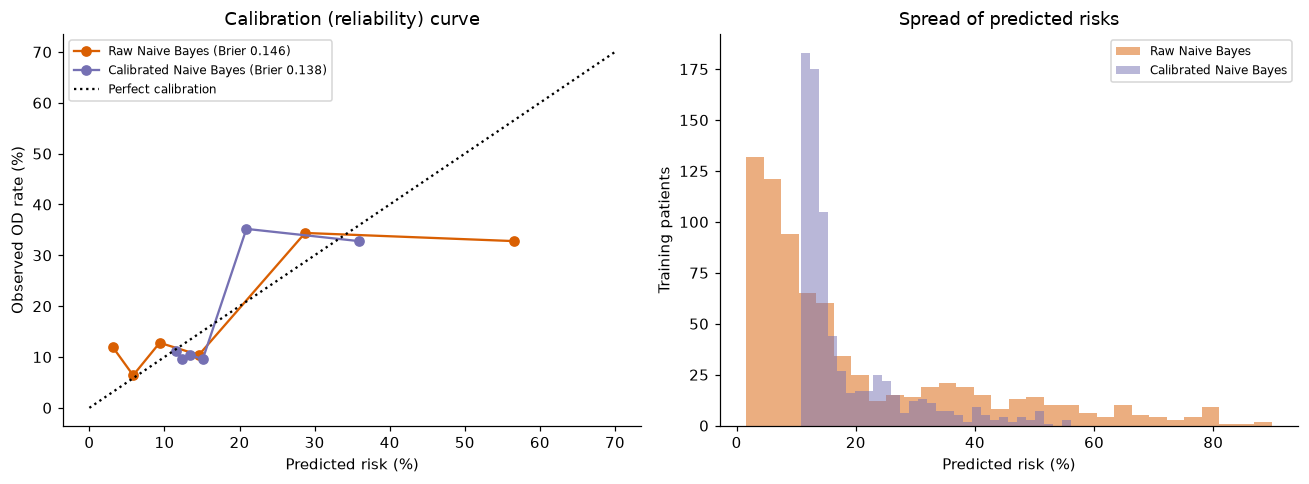

,Raw,Calibrated
Brier score,0.146,0.138
ROC AUC,0.678,0.679
PR AUC,0.339,0.338



Same policy rule on calibrated scores: 0.181 vs 0.231 (frozen raw-model threshold)


In [17]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
nb_cal = CalibratedClassifierCV(nb_pipe, method="sigmoid", cv=5)  # same method as the Responsible AI notebook

# Nested cross-validation on TRAINING patients only: the test set stays closed
p_raw = cross_val_predict(nb_pipe, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
p_cal = cross_val_predict(nb_cal,  X_train, y_train, cv=cv5, method="predict_proba")[:, 1]

# Left: calibration curves, raw vs calibrated, Brier score in the legend, perfect-calibration line (6 quantile bins)
# Right: histogram of predicted risks, raw vs calibrated
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
calibration_bins = {}
for scores, name, col in [(p_raw, "Raw Naive Bayes", C_OD),
                          (p_cal, "Calibrated Naive Bayes", C_NO)]:
    observed, predicted = calibration_curve(y_train, scores, n_bins=6, strategy="quantile")
    calibration_bins[name] = (observed, predicted)
    brier = brier_score_loss(y_train, scores)
    ax[0].plot(predicted * 100, observed * 100, "o-", color=col,
               label=f"{name} (Brier {brier:.3f})")
    ax[1].hist(scores * 100, bins=30, alpha=.5, color=col, label=name)
ax[0].plot([0, 70], [0, 70], "k:", label="Perfect calibration")
ax[0].set(xlabel="Predicted risk (%)", ylabel="Observed OD rate (%)",
          title="Calibration (reliability) curve")
ax[0].legend(fontsize=8)
ax[1].set(xlabel="Predicted risk (%)", ylabel="Training patients",
          title="Spread of predicted risks")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Build risk-group tables with the same quantile bins used by calibration_curve
raw_observed, raw_predicted = calibration_bins["Raw Naive Bayes"]
cal_observed, cal_predicted = calibration_bins["Calibrated Naive Bayes"]

def bin_table(y_true, p, n_bins=6):
    edges = np.percentile(p, np.linspace(0, 100, n_bins + 1))
    ids = np.searchsorted(edges[1:-1], p)
    d = pd.DataFrame({"bin": ids, "y": np.asarray(y_true), "p": p})
    return d.groupby("bin").agg(predicted=("p", "mean"), observed=("y", "mean"))

raw_bins = bin_table(y_train, p_raw)
cal_bins = bin_table(y_train, p_cal)
assert np.allclose(raw_bins["observed"], raw_observed)
assert np.allclose(raw_bins["predicted"], raw_predicted)
assert np.allclose(cal_bins["observed"], cal_observed)
assert np.allclose(cal_bins["predicted"], cal_predicted)

calibration_table = pd.DataFrame({
    ("Raw", "Predicted"): raw_bins["predicted"],
    ("Raw", "Observed"): raw_bins["observed"],
    ("Raw", "Gap (pp)"): 100 * (raw_bins["predicted"] - raw_bins["observed"]),
    ("Calibrated", "Predicted"): cal_bins["predicted"],
    ("Calibrated", "Observed"): cal_bins["observed"],
    ("Calibrated", "Gap (pp)"): 100 * (cal_bins["predicted"] - cal_bins["observed"]),
})
calibration_table.index = ["1 (lowest)", "2", "3", "4", "5", "6 (highest)"]
calibration_table.index.name = "Risk group"
calibration_formats = {
    (model, metric): "{:.1%}"
    for model in ("Raw", "Calibrated")
    for metric in ("Predicted", "Observed")
}
calibration_formats.update({(model, "Gap (pp)"): "{:+.1f}" for model in ("Raw", "Calibrated")})
display(calibration_table.style.format(calibration_formats).set_caption(
    "Calibration by risk group, training patients, nested 5-fold cross-validation"
))

metrics_table = pd.DataFrame({
    "Raw": [
        brier_score_loss(y_train, p_raw),
        roc_auc_score(y_train, p_raw),
        average_precision_score(y_train, p_raw),
    ],
    "Calibrated": [
        brier_score_loss(y_train, p_cal),
        roc_auc_score(y_train, p_cal),
        average_precision_score(y_train, p_cal),
    ],
}, index=["Brier score", "ROC AUC", "PR AUC"])
display(metrics_table.style.format("{:.3f}"))

# Print: threshold the SAME policy rule would pick on calibrated scores; frozen raw threshold stays unchanged
choice_cal = select_threshold(y_train, p_cal, MIN_RECALL, MAX_ALERTS_PER_1000)
threshold_cal = choice_cal["threshold"]
print(f"\nSame policy rule on calibrated scores: {threshold_cal:.3f} vs {threshold:.3f} (frozen raw-model threshold)")

**What to look for**

- **Before:** the table shows Naive Bayes is overconfident at both ends: the lowest-risk group is 3.1% predicted vs 12.0% observed, and the highest-risk group is 56.5% predicted vs 32.8% observed
- **After:** the curve moves closer to the diagonal for most groups and the histogram shows compressed predictions. The table shows the Brier score falls from 0.146 to 0.138, so the probabilities fit better overall
- **One group stays off:** risk group 5 is predicted at 20.9% but 35.2% of its patients have OD. Before calibration the same group was 28.7% predicted vs 34.4% observed, so the gap is wider now. Section 8.2 looks at it
- **Ranking:** the table shows ROC AUC changes from 0.678 to 0.679 and PR AUC from 0.339 to 0.338. These values are nearly unchanged while the probabilities shift
- **Threshold:** the same rule selects 0.181 on calibrated scores instead of 0.231. The number belongs to its model; sections 10 and 11 use the 5% prior model at its own threshold (0.060). Adopting a calibrated model means running the policy rule again
- **Limits:** calibration does not remove correlated findings or prove double counting caused the problem. The gain is modest and rests on 136 OD cases. In the Responsible AI notebook, calibration changed its logistic model only slightly, so the larger effect here is specific to Naive Bayes

**So what?** Use 0.181 only with the calibrated model, and validate the policy in the intended clinic. Better average calibration does not mean every group is calibrated (section 8.2). These results do not establish calibration at 5% prevalence.

### 8.2. After calibration, one risk group is still underpredicted: what now?

In the table above, risk group 5 is predicted at about 21% but about 35% of its patients have a recorded OD. Calibration improved the average, yet this group got worse. Four questions:

1. **Who is in this group?**
2. **Is the gap real or noise?**
3. **Does it change who gets flagged?**
4. **What could we do about it?**

We keep working on the 750 training patients. The test set stays closed. We also picked this group after seeing the table, so treat the p-values below as a guide, not as proof

,Patients,OD cases,"Predicted, raw","Predicted, calibrated",Observed,"Gap, calibrated (pp)"
All of group 5,125,44,28.8%,20.9%,35.2%,-14.3
Low income,81,38,30.2%,21.6%,46.9%,-25.3
Not low income,44,6,26.2%,19.6%,13.6%,+6.0


Group 5: 44 OD cases in 125 patients = 35.2% (95% interval 27.4% to 43.9%) vs 20.9% predicted
Chance of 44 or more cases if 20.9% were right: 0.0002 (0.001 after allowing for 6 groups)


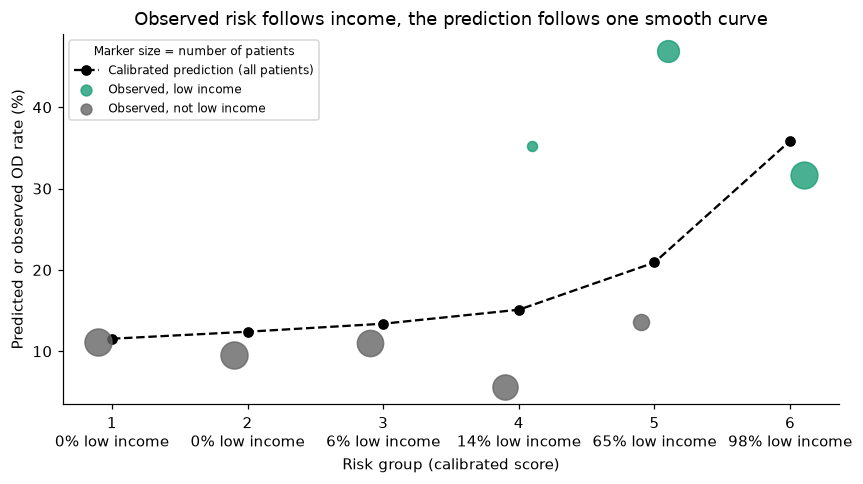

,Patients,"Predicted, raw","Predicted, calibrated",Observed,95% interval low,95% interval high
Low income,228,42.7%,28.7%,36.4%,30.4%,42.8%
Not low income,522,9.6%,13.6%,10.2%,7.8%,13.0%


ROC AUC of the calibrated score inside 'Low income': 0.50
ROC AUC of the calibrated score inside 'Not low income': 0.49
At the calibrated threshold 0.181: 95 of 125 group 5 patients are flagged, catching 41 of its 44 OD cases
Logistic regression, its risk group 5: predicted 25.5%, observed 36.0%


In [18]:
# 8.2 Look at the group that calibration still underpredicts (risk group 5 of 6)
# Same quantile groups as the table above. Training patients only: the test set stays closed
from scipy import stats

def risk_group(p, n_bins=6):
    edges = np.percentile(p, np.linspace(0, 100, n_bins + 1))
    return np.searchsorted(edges[1:-1], p)            # 0 = lowest ... 5 = highest, same rule as bin_table

y_arr = y_train.to_numpy()
low = X_train["Low_inc"].to_numpy() == 1
grp = risk_group(p_cal)
g5 = grp == 4                                         # risk group 5
assert np.allclose([p_cal[grp == k].mean() for k in range(6)], cal_bins["predicted"])   # matches the table above

# 1. Who is in group 5, and what happens to them?
rows = {}
for name, m in [("All of group 5", g5), ("Low income", g5 & low), ("Not low income", g5 & ~low)]:
    rows[name] = {"Patients": m.sum(), "OD cases": y_arr[m].sum(),
                  "Predicted, raw": p_raw[m].mean(), "Predicted, calibrated": p_cal[m].mean(),
                  "Observed": y_arr[m].mean()}
g5_table = pd.DataFrame(rows).T
g5_table["Gap, calibrated (pp)"] = 100 * (g5_table["Predicted, calibrated"] - g5_table["Observed"])
display(g5_table.style.format({"Patients": "{:.0f}", "OD cases": "{:.0f}", "Predicted, raw": "{:.1%}",
                               "Predicted, calibrated": "{:.1%}", "Observed": "{:.1%}", "Gap, calibrated (pp)": "{:+.1f}"})
        .set_caption("Risk group 5 of the calibrated model, split by income (raw = same patients, uncalibrated score)"))

# 2. Is the gap noise? How likely are this many OD cases if the calibrated risk were right?
n5, od5 = int(g5.sum()), int(y_arr[g5].sum())
lo5, hi5 = wilson_interval(od5, n5)
p_val = stats.binom.sf(od5 - 1, n5, p_cal[g5].mean())
print(f"Group 5: {od5} OD cases in {n5} patients = {od5 / n5:.1%} (95% interval {lo5:.1%} to {hi5:.1%}) vs {p_cal[g5].mean():.1%} predicted")
print(f"Chance of {od5} or more cases if {p_cal[g5].mean():.1%} were right: {p_val:.4f} ({min(1, 6 * p_val):.3f} after allowing for 6 groups)")

# 3. Observed risk by group and income: two flat bands against one smooth prediction
fig, ax = plt.subplots(figsize=(8, 4.5))
xs = np.arange(1, 7)
ax.plot(xs, [100 * p_cal[grp == k].mean() for k in range(6)], "k--o", label="Calibrated prediction (all patients)")
for is_low, name, col, dx in [(True, "Observed, low income", "#1b9e77", 0.1), (False, "Observed, not low income", "#666666", -0.1)]:
    ax.scatter([], [], s=50, color=col, alpha=.8, label=name)     # legend entry with a fixed marker size
    for k in range(6):
        m = (grp == k) & (low == is_low)
        if m.sum() >= 10:                             # skip tiny cells: 7 and 2 patients say nothing
            ax.scatter(k + 1 + dx, 100 * y_arr[m].mean(), s=m.sum() * 2.5, color=col, alpha=.8, zorder=3)
ax.set_xticks(xs, [f"{k + 1}\n{low[grp == k].mean():.0%} low income" for k in range(6)])
ax.set(xlabel="Risk group (calibrated score)", ylabel="Predicted or observed OD rate (%)",
       title="Observed risk follows income, the prediction follows one smooth curve")
ax.legend(fontsize=8, loc="upper left", title="Marker size = number of patients", title_fontsize=8)
plt.tight_layout(); plt.show()

# 4. Same question for all patients: predicted vs observed by income
rows = {}
for name, m in [("Low income", low), ("Not low income", ~low)]:
    k, n = int(y_arr[m].sum()), int(m.sum()); lo, hi = wilson_interval(k, n)
    rows[name] = {"Patients": n, "Predicted, raw": p_raw[m].mean(), "Predicted, calibrated": p_cal[m].mean(),
                  "Observed": k / n, "95% interval low": lo, "95% interval high": hi}
display(pd.DataFrame(rows).T.style.format({"Patients": "{:.0f}", "Predicted, raw": "{:.1%}", "Predicted, calibrated": "{:.1%}",
                                           "Observed": "{:.1%}", "95% interval low": "{:.1%}", "95% interval high": "{:.1%}"})
        .set_caption("All 750 training patients: predicted vs observed OD rate by income"))

# 5. Does the score rank patients inside an income group? (0.5 = no better than chance)
for name, m in [("Low income", low), ("Not low income", ~low)]:
    print(f"ROC AUC of the calibrated score inside '{name}': {roc_auc_score(y_arr[m], p_cal[m]):.2f}")

# 6. Does it change who gets flagged? Apply the calibrated threshold from the cell above
flag = p_cal >= threshold_cal
print(f"At the calibrated threshold {threshold_cal:.3f}: {int((flag & g5).sum())} of {n5} group 5 patients are flagged, "
      f"catching {int((flag & g5 & (y_arr == 1)).sum())} of its {od5} OD cases")

# 7. Is this only a Naive Bayes problem? Same check for logistic regression (uncalibrated, same folds)
lr_check = Pipeline([("prep", preprocess), ("lr", LogisticRegression(max_iter=1000))])
p_lr = cross_val_predict(lr_check, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
g_lr = risk_group(p_lr) == 4
print(f"Logistic regression, its risk group 5: predicted {p_lr[g_lr].mean():.1%}, observed {y_arr[g_lr].mean():.1%}")

### What we see

- **Risk groups largely follow income:** 81 of 125 patients (65%) in group 5 are low income, rising to 98% in group 6. The model's risk ranking is strongly associated with income
- **Group 5 has a substantial prediction gap:** Among low-income patients, 46.9% have recorded opioid use disorder (OD), versus 13.6% of other patients. Yet their average predicted risks are similar, around 20–22%
- **The gap deserves attention:** Group 5 has 44 OD cases, with an observed rate of 35.2% versus 20.9% predicted. Its approximate 95% confidence interval is 27–44%. However, we identified this group after seeing the results, so this is exploratory evidence, not proof of a persistent error
- **Calibration shifts rather than eliminates the income gap:** Across all 228 low-income patients, the raw model predicts 42.7% risk versus 36.4% observed. Calibration lowers the prediction to 28.7%. For the other 522 patients, it raises predictions from 9.6% to 13.6%, versus 10.2% observed
- **The model adds little ranking information within income groups:** The area under the receiver operating characteristic curve (ROC AUC) is 0.49 and 0.50, where 0.50 means chance-level ranking. In this cohort, most of the model's ability to distinguish OD cases appears to come from income
- **This is not unique to Naive Bayes:** Logistic regression also shows underprediction in its fifth risk group, suggesting the problem is not explained solely by Naive Bayes' independence assumption

### Why doesn't sigmoid calibration fix this?

Sigmoid calibration learns **one smooth correction** that maps the model's original scores to adjusted probabilities. Patients with the same score receive the same correction, regardless of income.

But our data show very different observed OD rates for low-income and other patients with similar predicted scores. One score-only correction cannot fully account for both patterns.

As a result, calibration improves the model overall but leaves some groups worse off. Groups 2–4 are now overestimated by 3–5.5 percentage points, while group 5 is underestimated by 14.3 points.

### What does this mean?

- **Probabilities remain unreliable for some patients:** In group 5, the average prediction of 21% masks observed rates of 47% for low-income patients and 14% for others. These are group averages, not individual risk estimates
- **Clinical decisions may still work:** At the calibrated threshold (0.181), the model flags 95 of 125 patients in group 5 and catches 41 of 44 recorded OD cases. Detecting cases and estimating accurate probabilities are different tasks
- **Equity matters:** Prediction errors differ by income. Section 11 examines who is flagged or missed; here we examine whose risk is misestimated
- **We need independent confirmation:** These patterns come from cross-validated training predictions. They may not persist in new patients

### What could we do?

| Option | What it means | Limitation |
|---|---|---|
| **Keep sigmoid calibration** | Retain the simpler correction that improves overall accuracy | Group 5 remains underestimated |
| **Try isotonic calibration** | Learn a more flexible, step-like correction instead of one smooth curve | Can overfit with limited data and cannot necessarily fix income-specific differences |
| **Calibrate by income** | Learn different corrections for low-income and other patients | Needs enough cases per group, fairness review, and independent validation. May change patient rankings |
| **Improve the underlying model** | Use better clinical findings or a different algorithm to capture risk beyond income | Requires retraining, a new threshold, and evaluation |
| **Validate on new patients** | Check whether the observed gaps persist before changing the model | Requires independent patient data |

### So what?

**Better overall calibration does not guarantee accurate probabilities for every patient group.**

For this teaching notebook, we keep sigmoid calibration because it improves average probability accuracy (Brier score 0.146 → 0.138), while clearly reporting its limitations.

In practice, we would first check whether these differences persist in independent patients. Only then would we consider changing the calibration method or the model.

**Important:** This analysis uses the cohort's 18% OD prevalence. It does not establish that the model is calibrated for the target population with an external 5% prior.

## 9. Comparison across five models

<img src="media/models.png" alt="Tension between black box and interpretable algorithms" width="640">


### Why these five models?

A hospital choosing a risk tool faces one question: **how much complexity is worth it?** These five models range from a one-finding rule to a flexible black box. We compare them to see what each extra step buys, not to crown a winner

| Model | Role in the comparison | Clinical question it answers |
|---|---|---|
| **NB, all features** (Naive Bayes, the model used so far) | Reference | How good is the model we have studied? |
| **NB, `Low_inc` only** | Simplest benchmark, close to a "flag low income" rule | Do the other 19 findings add anything to Naive Bayes? |
| **Logistic regression** | Workhorse of clinical risk scores. It weights findings together and does not assume they are independent | Does a model that does not assume independence do better? |
| **Decision tree (depth 3)** | A few if-then rules a clinician can read at the bedside | Is a short, transparent rule enough? |
| **Random Forest** | Flexible benchmark that can capture interactions between findings, but is hard to explain | Is there signal our simpler models miss? |

**What we want to learn**
- Whether more complexity improves **case finding** (PR AUC) and **probability quality** (Brier score) enough to justify losing transparency
- Whether the signal comes from income alone, from many findings added together, or from interactions between findings

**How to read the result**
- If Random Forest is clearly better, ask why and test it before adopting it
- If the models are close, prefer the simplest and most transparent one
- Whatever the result, check who is flagged and missed (section 11) before any use

These results describe this dataset only. We are not choosing a model: nothing is tuned, and sections 10 and 11 keep using Naive Bayes with the 5% prior

We compare the models with **10 repeats of stratified 5-fold cross-validation** (50 fits per model). Every model uses the same 50 fold splits, and each pipeline fits preprocessing on its training fold. The full-feature Naive Bayes model learns its prior within each training fold. The one-feature comparison fits a separate Bernoulli Naive Bayes model using `Low_inc` only, unlike the raw `Low_inc` baseline in section 3. Nothing is tuned or selected from these results (section 3). This comparison uses the cohort as it is (18% OD) on purpose, so every model sees the same data. Brier scores describe this cohort, not a 5% clinic

Metric references: [scikit-learn precision-recall guide](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html), [ROC AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html), and [Brier score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html)


,PR AUC (Average Precision),PR AUC sd,ROC AUC,ROC AUC sd,Brier score (lower=better),Brier score sd
"NB, all features",0.354,0.048,0.692,0.049,0.145,0.011
"NB, Low_inc only",0.306,0.028,0.701,0.030,0.132,0.005
Logistic regression,0.359,0.050,0.705,0.038,0.136,0.006
Decision tree (depth 3),0.325,0.040,0.711,0.040,0.137,0.007
Random Forest,0.475,0.059,0.787,0.033,0.127,0.004


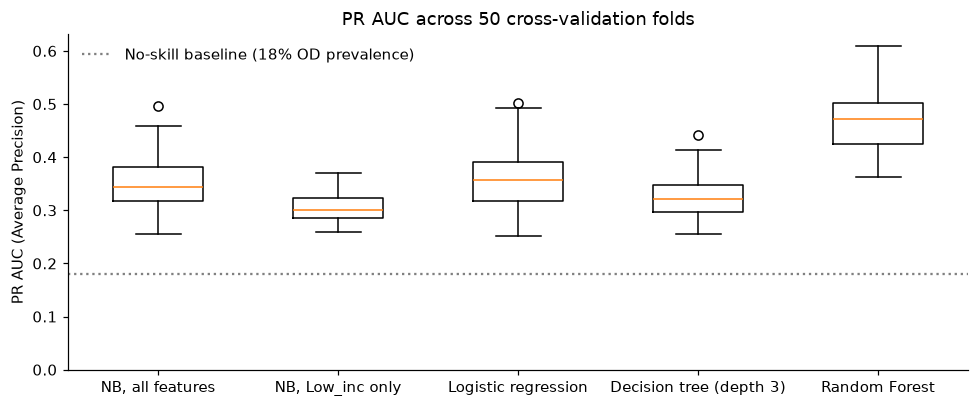

In [19]:
lr_pipe = Pipeline([("prep", preprocess), ("lr", LogisticRegression(max_iter=1000))])

models = {
    "NB, all features": nb_pipe,
    "NB, Low_inc only": Pipeline([("sel", ColumnTransformer([("li", "passthrough", ["Low_inc"])])),
                                  ("nb", BernoulliNB())]),
    "Logistic regression": lr_pipe,
    "Decision tree (depth 3)": Pipeline([("prep", preprocess),
                                         ("dt", DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=0))]),
    "Random Forest": Pipeline([("prep", preprocess),
                               ("rf", RandomForestClassifier(n_estimators=200, max_depth=5,
                                                             min_samples_leaf=10, random_state=0,
                                                             n_jobs=-1))]),
}

# Materialize the folds once so every model sees identical train/test patients
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
cv_splits = list(rcv.split(X, y))
res = {n: cross_validate(m, X, y, cv=cv_splits,
                         scoring=["roc_auc", "average_precision", "neg_brier_score"])
       for n, m in models.items()}

summary = pd.DataFrame({n: {"PR AUC (Average Precision)": r["test_average_precision"].mean(),
                            "PR AUC sd": r["test_average_precision"].std(),
                            "ROC AUC": r["test_roc_auc"].mean(),
                            "ROC AUC sd": r["test_roc_auc"].std(),
                            "Brier score (lower=better)": -r["test_neg_brier_score"].mean(),
                            "Brier score sd": r["test_neg_brier_score"].std()} for n, r in res.items()}).T
display(summary.style.format(precision=3))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot([r["test_average_precision"] for r in res.values()])
ax.set_xticks(range(1, len(res) + 1), list(res))
baseline = y.mean()
ax.axhline(baseline, c="grey", ls=":",
           label=f"No-skill baseline ({baseline:.0%} OD prevalence)")
ax.set_ylim(bottom=0)
ax.set(ylabel="PR AUC (Average Precision)",
       title="PR AUC across 50 cross-validation folds")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()


#### What do we sacrifice when models become more complex?

**Clinical question:** If a patient is classified as low income and all other findings stay the same, how does the predicted OD risk change?

| | Naive Bayes | Random Forest |
|---|---|---|
| **What can we extract?** | An odds ratio for `Low_inc` (Section 5): 5.0 | No single coefficient for `Low_inc` |
| **What can we tell a clinician?** | "Low income multiplies the predicted odds of OD by approximately 5" | "Income matters, but its effect depends on the patient's other findings" |
| **Is the effect consistent?** | Yes. The same odds multiplier applies to every patient | Not necessarily. Different combinations of findings can produce different effects |
| **Can we explain the model's calculation?** | Directly. We can multiply the likelihood ratios step by step | We can inspect its 200 trees or use explanation tools, but the overall rule is much harder to summarize |

| | Naive Bayes | Random Forest |
|---|---|---|
| **Cross-validated PR AUC** | 0.354 | 0.475 |

**The trade-off:** Random Forest finds stronger predictive patterns in this dataset. In exchange, we lose the ability to describe each finding with one fixed odds multiplier.

**Two points to keep in mind**
- 5× odds does not mean 5× probability, and it does not show that income causes OD
- Random Forest is harder to interpret, not impossible to explain. Feature importance and patient-level explanations help, but they are not equivalent to a fixed odds multiplier

**So what?** Better predictions may justify more complexity. Clinicians must weigh that gain against the loss of a simple, transparent explanation.

**Takeaways** (one per question above)

- **Do the other 19 findings/ features help Naive Bayes?** Only a little. Compared with `NB, Low_inc only`, they raise PR AUC (0.354 vs 0.306), but not ROC AUC (0.692 vs 0.701), and they worsen the Brier score (0.145 vs 0.132)
- **Does logistic regression, which does not assume independence, do better?** Not for case finding: its PR AUC is almost the same (0.359 vs 0.354). Its Brier score is better (0.136 vs 0.145), which fits the overconfidence in section 8. The two models differ in more than independence, so this cannot show that dependence between findings is the cause
- **Is a short rule enough?** It is close to the simple models and far from Random Forest. The depth-3 tree has PR AUC 0.325 against 0.354 (Naive Bayes) and 0.359 (logistic regression), within fold variation, and a similar Brier score (0.137)
- **Is there signal the simpler models miss?** Probably. Random Forest has the highest PR AUC (**0.475**) and ROC AUC (**0.787**) and the lowest Brier score (**0.127**). Its gain is consistent with interactions between findings, which logistic regression cannot use. Other differences between the algorithms could also explain it, and we have not tested this. It does not show how many patients are flagged or missed at one threshold
- **How firm is this?** Fold standard deviations are not confidence intervals, so nothing here is a significance test. Random Forest's PR AUC lead (0.12 to 0.17 over the others) is the only gap clearly larger than the fold standard deviations (0.03 to 0.06). Brier scores differ by 0.018 at most (0.127 to 0.145)

**Key point:** A more complex model may find more cases, but it costs transparency and does not show who is missed. Check who is flagged and missed (section 11) before choosing one

## 10. What does our threshold mean in practice?

A patient is flagged for **clinical review** when the 5% prior model gives them an OD probability of **0.060 (6%) or more**. Section 4.2 set this threshold with the same rule as the Responsible AI notebook, applied to a clinic where 5% of patients have OD. A flag only starts a review. It never means refusing or tapering pain treatment

**Why we project to 5%.** Our cohort has 18% OD, but the clinic where we would use the model has about 5%. Counts from the cohort show who the model catches. They misstate the workload of a 5% clinic, because with fewer OD cases a larger share of flags are false alarms. A clinic needs the 5% numbers: how many reviews per 1,000 patients, and how many for each case found. We have no data from a 5% clinic, so we estimate these numbers from the cohort. This estimate is a **projection**

We look at 1,000 patients in two settings:
- **Our cohort, as observed:** 181 of 1,000 patients have OD. These are real counts
- **The target population, projected:** 50 of 1,000 patients have OD (5%). These are estimates, not observed data. The cell below the table shows how we calculate them and what they assume

### 10.1. What happens to 1,000 patients?

Each patient is scored by a model that did not see them (5-fold cross-validation). These patients also helped set the threshold, so the counts describe how the policy behaves. They are not a new test

In [20]:
from scipy.special import expit, logit

# Scores for all 1,000 patients, each from a model that did not see that patient
cv_nb5 = cross_val_predict(nb_external_prior, X, y, cv=cv5, method="predict_proba")[:, 1]
cv_lr = cross_val_predict(lr_pipe, X, y, cv=cv5, method="predict_proba")[:, 1]

def outcomes(y_true, score, t, prevalence=None):
    # Sensitivity and false-positive rate come from the cohort; prevalence sets how many of 1,000 have OD
    y_true, flag = np.asarray(y_true), np.asarray(score) >= t
    sens = (flag & (y_true == 1)).sum() / (y_true == 1).sum()
    fpr = (flag & (y_true == 0)).sum() / (y_true == 0).sum()
    p = y_true.mean() if prevalence is None else prevalence
    caught, missed, false_alarms = 1000 * p * sens, 1000 * p * (1 - sens), 1000 * (1 - p) * fpr
    return {"patients with OD": 1000 * p, "flagged": caught + false_alarms, "OD cases caught": caught,
            "OD cases missed": missed, "false alarms": false_alarms,
            "reviews per case found": (caught + false_alarms) / caught,
            "flags that are OD": caught / (caught + false_alarms)}

nf = pd.DataFrame({"Cohort, as observed (18% OD)": outcomes(y, cv_nb5, threshold_ext),
                   "Target population, projected (5% OD)": outcomes(y, cv_nb5, threshold_ext, P_TARGET)}).T
display(nf.style.format("{:.0f}", subset=["patients with OD", "flagged", "OD cases caught", "OD cases missed", "false alarms"])
        .format("{:.1f}", subset=["reviews per case found"]).format("{:.0%}", subset=["flags that are OD"])
        .set_caption(f"Out of 1,000 patients, 5% prior model, cross-validated, threshold {threshold_ext:.3f}"))

# Does the projected workload meet the policy rule?
tp_c, n_od = int(((cv_nb5 >= threshold_ext) & (y == 1)).sum()), int((y == 1).sum())
lo, hi = wilson_interval(tp_c, n_od)
proj = nf.iloc[1]
print(f"Policy rule in a 5% population: recall {tp_c / n_od:.0%} (95% CI {lo:.0%} to {hi:.0%}; floor {MIN_RECALL:.0%}), "
      f"{proj['flagged']:.0f} reviews per 1,000 (limit {MAX_ALERTS_PER_1000})")

,patients with OD,flagged,OD cases caught,OD cases missed,false alarms,reviews per case found,flags that are OD
"Cohort, as observed (18% OD)",181,311,115,66,196,2.7,37%
"Target population, projected (5% OD)",50,259,32,18,227,8.2,12%


Policy rule in a 5% population: recall 64% (95% CI 56% to 70%; floor 60%), 259 reviews per 1,000 (limit 300)


**How the projected row is calculated**

Sensitivity and false-alarm rate describe how the model treats patients with OD and patients without OD, so they do not depend on how many of each there are. We take them from the cohort, at threshold 0.060:
- **Sensitivity:** 115 of the 181 patients with OD are flagged (64%)
- **False-alarm rate:** 196 of the 819 patients without OD are flagged (24%)

In a 5% clinic, 1,000 patients means 50 with OD and 950 without:
- **OD cases caught:** 50 × 64% = about 32
- **False alarms:** 950 × 24% = about 227
- **Flagged:** 32 + 227 = about 259, which is about 8 reviews for each case found. The table uses unrounded rates, so it shows 8.2

Only the number of patients with and without OD changes. The two rates stay the same. This is the assumption we cannot test with this dataset (section 10.3)

### 10.2. Clinical utility check at 5% prevalence

The decision curve asks whether the model beats two simple policies: review everyone or review no one. **Net benefit** counts true positives and subtracts false positives, weighted by the harm ratio that the threshold implies:

$$\text{Net benefit} = \frac{TP}{n} - \frac{FP}{n} \times \frac{t}{1-t}$$

We compute it for the projected 5% population, from the cohort's sensitivity and false-positive rate. Logistic regression learned the cohort's 18% base rate, so we give it the same 5% prior by shifting its log-odds.

- Our threshold **0.060** came from recall and review capacity, not from a clinical harm estimate. It still implies one: $t/(1-t) = 0.06$, so one false alarm costs 0.06 of a true case found. Put differently, a missed case counts about 16 times as much as one extra review
- A harm ratio is a clinical judgement and does not depend on prevalence. Our threshold was set by capacity, so it only implies a ratio. At 5% prevalence the same policy implies about 16:1, against 3.3:1 in our cohort (threshold 0.231). To keep the same recall in a rarer-OD clinic, we accept more false alarms per case found. A clinic that judges the ratio to be lower should use a higher threshold
- The Responsible AI notebook (section 7.1.3) tested ratios of 2:1, 5:1 and 10:1. A clinic with a different ratio could reach a different conclusion
- We read the curve at 0.060 only and do not use it to pick a new threshold

Reference: [Vickers & Elkin (2006), decision curve analysis](https://pmc.ncbi.nlm.nih.gov/articles/PMC2577036/)

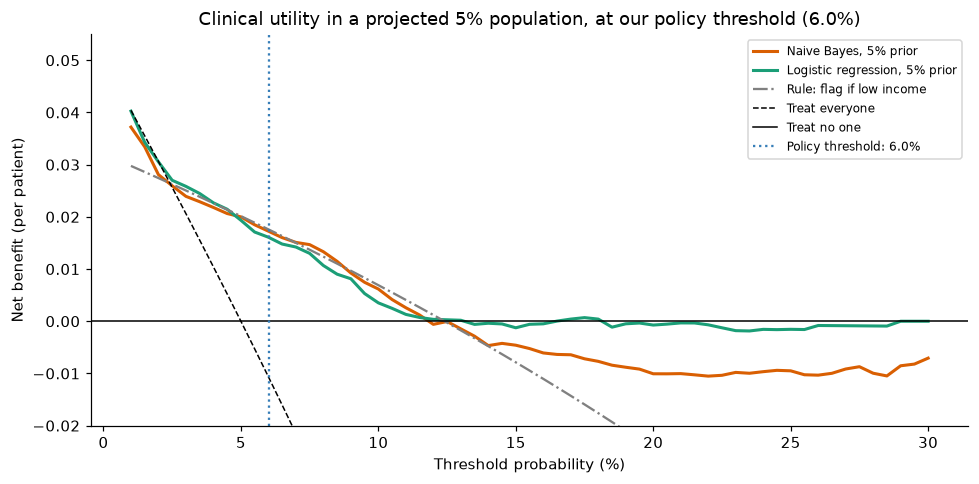

,"Net benefit per 1,000 patients at 6.0%"
"Naive Bayes, 5% prior",17.2
"Logistic regression, 5% prior",16.1
Rule: flag if low income,17.6
Treat everyone,-10.8
Treat no one,0.0


In [21]:
ts = np.linspace(0.01, 0.30, 59)

def net_benefit(y_true, s, t, prevalence=None):
    # Per-patient net benefit; sensitivity and false-positive rate from the cohort, prevalence sets the setting
    y_true, flag = np.asarray(y_true), np.asarray(s) >= t
    sens = (flag & (y_true == 1)).sum() / (y_true == 1).sum()
    fpr = (flag & (y_true == 0)).sum() / (y_true == 0).sum()
    p = y_true.mean() if prevalence is None else prevalence
    return p * sens - (1 - p) * fpr * t / (1 - t)

# Same prior shift for logistic regression: add the log of the odds ratio (5% odds / cohort odds) to its log-odds
shift = np.log((P_TARGET / (1 - P_TARGET)) / (y.mean() / (1 - y.mean())))
cv_lr5 = expit(logit(cv_lr) + shift)

P = P_TARGET
nb_c = [net_benefit(y, cv_nb5, t, P) for t in ts]
lr_c = [net_benefit(y, cv_lr5, t, P) for t in ts]
li_c = [net_benefit(y, X["Low_inc"], t, P) for t in ts]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(ts * 100, nb_c, c=C_OD, lw=2, label="Naive Bayes, 5% prior")
ax.plot(ts * 100, lr_c, c="#1b9e77", lw=2, label="Logistic regression, 5% prior")
ax.plot(ts * 100, li_c, c="grey", lw=1.5, ls="-.", label="Rule: flag if low income")
ax.plot(ts * 100, P - (1 - P) * ts / (1 - ts), "k--", lw=1, label="Treat everyone")
ax.axhline(0, c="k", lw=1, label="Treat no one")
ax.axvline(threshold_ext * 100, c="#377eb8", ls=":", lw=1.5, label=f"Policy threshold: {threshold_ext:.1%}")
ax.set(ylim=(-0.02, P + .005), xlabel="Threshold probability (%)", ylabel="Net benefit (per patient)",
       title=f"Clinical utility in a projected 5% population, at our policy threshold ({threshold_ext:.1%})"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

t0 = threshold_ext
utility = pd.Series({
    "Naive Bayes, 5% prior": net_benefit(y, cv_nb5, t0, P),
    "Logistic regression, 5% prior": net_benefit(y, cv_lr5, t0, P),
    "Rule: flag if low income": net_benefit(y, X["Low_inc"], t0, P),
    "Treat everyone": P - (1 - P) * t0 / (1 - t0),
    "Treat no one": 0.0,
}, name=f"Net benefit per 1,000 patients at {t0:.1%}") * 1000
display(utility.to_frame().style.format(precision=1))

**Reading the results at the 5% model's policy threshold (0.060)**

- **Cohort, as observed (18% OD):** among 1,000 patients, the model flags **311**, catches **115 of 181 OD cases (64%)**, misses **66**, and raises **196 false alarms**. That is about **2.7 reviews per OD case found**
- **Projected to a 5% population:** among 1,000 patients, 50 have OD. The model flags about **259**, catches about **32**, misses about **18**, and raises about **227 false alarms**. That is about **8.2 reviews per OD case found**, and only about **12% of flags** are OD (37% in the cohort)
- **Why the burden grows:** sensitivity (64%) and false-positive rate (24%) stay the same, but there are far fewer cases to find among many more patients without OD. A rare condition makes false alarms dominate, however good the model
- **Capacity and recall:** about 259 reviews per 1,000 is within the 300 limit, and recall of 64% is above the 60% floor, but its 95% interval (56% to 70%) includes values below the floor
- **Net benefit** per 1,000 patients is about **17.2** for Naive Bayes, **16.1** for logistic regression and **17.6** for the `Low_inc` rule, against **-10.8** for treating everyone and 0 for no one. The model beats both simple policies if a missed case counts about 16 times as much as one extra review, but it adds no clear utility beyond the `Low_inc` rule. This does not mean acting on income is appropriate; section 11 examines its consequences
- These are synthetic results that assume the cohort's likelihoods hold in a 5% population. Section 10.3 tests what we can test here, and what we cannot

### 10.3. Can we test the 5% prior with this data?

Only part of it. We **cannot** test whether the likelihoods hold in a real 5% clinic: that needs data from that clinic. We **can** test the mechanics of the prior shift. We build a 5% **pseudo-clinic** from our own cohort by down-weighting patients with OD until they are 5% of the total. The likelihoods are the same by construction, so a correct prior shift should work there

In [22]:
# Pseudo-clinic: patients with OD get a weight below 1 so that they make up 5% of the weighted cohort
w_od = P_TARGET * (y == 0).sum() / ((1 - P_TARGET) * (y == 1).sum())
wt = np.where(y == 1, w_od, 1.0)
cv_nb18 = cross_val_predict(nb_pipe, X, y, cv=cv5, method="predict_proba")[:, 1]    # cohort-prior model

def weighted_groups(score, n_groups=6):
    # Six risk groups of equal weight, lowest to highest predicted risk
    order = np.argsort(score)
    group = np.empty(len(score), int)
    group[order] = np.minimum((np.cumsum(wt[order]) / wt.sum() * n_groups).astype(int), n_groups - 1)
    rows = []
    for g in range(n_groups):
        m = group == g
        rows.append({"Predicted": np.average(score[m], weights=wt[m]), "Observed": np.average(np.asarray(y)[m], weights=wt[m])})
    return pd.DataFrame(rows, index=["1 (lowest)", "2", "3", "4", "5", "6 (highest)"]).rename_axis("Risk group")

compare = pd.DataFrame({
    "Cohort prior (18%)": {"Mean predicted risk": np.average(cv_nb18, weights=wt),
                           "Brier score": brier_score_loss(y, cv_nb18, sample_weight=wt)},
    "5% prior": {"Mean predicted risk": np.average(cv_nb5, weights=wt),
                 "Brier score": brier_score_loss(y, cv_nb5, sample_weight=wt)},
    "Predict 5% for everyone": {"Mean predicted risk": P_TARGET,
                                "Brier score": brier_score_loss(y, np.full(len(y), P_TARGET), sample_weight=wt)},
}).T
display(compare.style.format({"Mean predicted risk": "{:.1%}", "Brier score": "{:.4f}"})
        .set_caption(f"Pseudo-clinic: observed OD rate is {np.average(y, weights=wt):.1%}"))

groups5 = weighted_groups(cv_nb5)
groups5["Gap (pp)"] = 100 * (groups5["Predicted"] - groups5["Observed"])
display(groups5.style.format({"Predicted": "{:.1%}", "Observed": "{:.1%}", "Gap (pp)": "{:+.1f}"})
        .set_caption("5% prior model, calibration by risk group in the pseudo-clinic"))

,Mean predicted risk,Brier score
Cohort prior (18%),17.8%,0.0846
5% prior,6.4%,0.0499
Predict 5% for everyone,5.0%,0.0475


,Predicted,Observed,Gap (pp)
Risk group,,,
1 (lowest),0.8%,3.2%,-2.4
2,1.3%,2.0%,-0.7
3,2.1%,2.1%,-0.0
4,3.1%,2.1%,+0.9
5,6.9%,8.3%,-1.4
6 (highest),24.3%,12.2%,+12.2


**What this shows**
- **The prior shift works on average:** the 5% model predicts about 6% on average where the true rate is 5%. The cohort-prior model predicts about 18%
- **The probabilities are still overconfident at the top:** the highest-risk group is predicted at about 24% but observed at about 12%. This is the double-counting problem of section 8, now at 5% prevalence. It also explains why the Naive Bayes net benefit drops below zero at high thresholds in section 10.2
- **Its Brier score is no better than predicting 5% for everyone.** The ranking carries signal; the exact percentages do not. Use the scores to order patients, and calibrate locally before showing a patient a percentage
- **Limit:** this tests the arithmetic only. A real clinic can differ in patient mix, coding and care pathways

**How is this tested in practice?**
1. **Silent mode:** run the model on the clinic's own patients for a period without acting on it, and record what happens to them
2. **Measure locally:** estimate prevalence, sensitivity, false-positive rate and calibration from those outcomes
3. **Update what does not transfer:** set the prior or recalibrate, then re-run the threshold policy on local data (section 4.2)
4. **Monitor after go-live:** prevalence, calibration and who is flagged all drift, so re-check on a schedule

When outcome labels are not yet available, the new prevalence can be estimated from unlabelled patients ([Saerens et al., 2002](https://mlanthology.org/neco/2002/saerens2002neco-adjusting)). The need is real: an [external validation of a widely used hospital sepsis model](https://jamanetwork.com/journals/jamainternalmedicine/fullarticle/2781313) found much weaker performance than its developer reported, and calibration is the usual weak point ([Van Calster et al., 2019](https://pmc.ncbi.nlm.nih.gov/articles/PMC6912996))

## 11. Equity: what if the main signal is income?

This subgroup analysis uses the 5% prior model at its **0.060** threshold, the same one as in section 10. We report the two rates that do not depend on prevalence: **recall** (share of patients with OD who are flagged) and **false-alarm rate** (share of patients without OD who are flagged).

If low income drives most of the score, the model will mostly flag low-income patients. Let's check who gets flagged at our policy threshold.

In [23]:
g = pd.DataFrame({"Low_inc": X["Low_inc"].map({1: "Low income", 0: "Not low income"}), "y": y, "flag": cv_nb5 >= threshold_ext})
rows = []
for grp, d in g.groupby("Low_inc"):
    od, no_od = d[d.y == 1], d[d.y == 0]
    rows.append({"group": grp, "patients": len(d),
                 "with OD": len(od), "caught": int(od.flag.sum()), "recall": od.flag.mean(),
                 "without OD": len(no_od), "false alarms": int(no_od.flag.sum()), "false-alarm rate": no_od.flag.mean()})
out = pd.DataFrame(rows).set_index("group")
display(out.style.format({"patients": "{:.0f}", "with OD": "{:.0f}", "caught": "{:.0f}", "recall": "{:.0%}",
                          "without OD": "{:.0f}", "false alarms": "{:.0f}", "false-alarm rate": "{:.0%}"}))

,patients,with OD,caught,recall,without OD,false alarms,false-alarm rate
group,,,,,,,
Low income,311,116,109,94%,195,167,86%
Not low income,689,65,6,9%,624,29,5%


**What the table shows:** in the low-income group the model catches **109 of 116 OD cases (94%)**, but it also flags **167 of 195 patients without OD (86%)**. In the other group it catches only **6 of 65 (9%)** and flags **29 of 624 (5%)**. Recall and false-alarm rate carry over to a 5% population only if the likelihoods transfer. The size of each group there may differ.

**Discussion points for clinicians and policymakers**

- **Association does not prove causation**: income marks risk in this dataset, but these results do not explain why
- **Who carries the burden of false alarms?** Among patients without OD, 167 of 195 low-income patients (86%) are flagged, against 29 of 624 others (5%). Restrictive actions could harm low-income patients most; supportive actions such as follow-up attach a different consequence to the same flag
- **Who is missed?** Most patients with OD outside the low-income group are missed, creating a blind spot
- **Same input, different policy**: the ethics depend on the action attached to the score

## 12. How could we improve this model?

1. **Use better clinical features**: consider dose, duration, previous overdose, mental-health history, and concurrent sedative use. Check timing and clinical relevance; the forest's stronger ranking does not establish future prediction
2. **Separate the algorithm from the features**: within Naive Bayes, section 9 already shows the extra findings add little. Random Forest vs `Low_inc`-only Naive Bayes changes both algorithm and feature set. Fitting Random Forest with all findings vs `Low_inc` only would show whether the other findings add predictive value beyond income. It would not show whether interactions matter
3. **Check probability estimates separately**: Random Forest has the lowest mean Brier score, but its lead is small relative to fold variability. Compare calibration across models and validate in the intended population
4. **Audit by income group before choosing a model**: section 11 shows that only 6 of 65 OD cases outside the low-income group are caught (9% recall). Treat that recall as the number to beat, and check whether Random Forest improves it
5. **Validate the transfer to the target population**: collect a small validation sample from the clinic, check that the 5% prior and the likelihoods hold, and re-run the policy rule there (steps in section 10.3). This is the assumption behind every projection in sections 10 and 11

Check feature quality, probability accuracy and who is missed, even when a more complex model ranks this cohort better


## 13. Summary

| Concept | What we saw |
|---|---|
| Prior | The cohort has 18% OD, the target population about 5% (external research). The cohort teaches the likelihoods; the external prior sets the starting point. Sections 7, 10 and 11 use the 5% prior; the cohort's 18% appears only in comparisons (sections 3, 4 and 7), in calibration (8.1) and in the model comparison (9). The 5% model is not calibrated or validated in a real 5% population here |
| Likelihoods | Each finding has an individual LR from its sensitivity and 1 minus specificity. Their product is the combined LR (Bayes factor). Prior odds × combined LR = posterior odds. None of these LRs change when only the prior changes |
| Smoothing | Laplace smoothing corresponds to a Beta(1, 1) prior on each feature probability |
| Naive assumption | Correlated features can double-count evidence and produce overconfident probabilities |
| Performance | Random Forest leads on mean PR AUC (0.475) and ROC AUC (0.787); its mean Brier score is 0.127. Naive Bayes with all findings beats `Low_inc` only on PR AUC but not on ROC AUC or Brier. These synthetic cohort results do not establish clinical value |
| Calibration | Sigmoid calibration improves Naive Bayes probabilities (Brier 0.146 to 0.138) with nearly unchanged AUCs (ROC AUC 0.678 to 0.679; PR AUC 0.339 to 0.338). One risk group, mostly low-income patients, stays underpredicted (about 21% predicted vs 35% observed, section 8.2). The calibrated scores select 0.181, so keep their own threshold. Results use the learned prior and do not establish calibration at 5% prevalence |
| Decisions | The same policy rule gave separate thresholds: 0.231 for the cohort prior and 0.060 for the 5% prior, which also uses 5% prevalence for workload. Projected to 1,000 patients at 5% OD, the 5% model flags about 259, catches about 32 of 50 cases and raises about 227 false alarms (8.2 reviews per case found). Keep each threshold with its model, prior and prevalence |
| Transfer | Projections assume the cohort's sensitivity and false-positive rate hold in the target population. A 5% pseudo-clinic built from the cohort confirms the prior shift on average (6.4% predicted vs 5% observed), but shows overconfidence at the top and a Brier score no better than predicting 5% for everyone. Only local validation (silent mode, local calibration, monitoring) can confirm transfer |
| Ethics | Audit who is flagged and missed, and attach an action that supports patients |

## 14. Open Questions

1. A clinic where 40% of patients have OD wants to use this model. What should change, and what should not? (Hint: prior vs likelihoods)
2. Pick a test patient with a post-test probability around 15% **under the 5% prior**. Explain their result to a general practitioner in three sentences, without the words "odds" or "likelihood"
3. Remove `Low_inc` and retrain. What happens to **both ROC AUC and PR AUC**? What does that tell you about the other 19 features?
4. Replace the binarized `rx_ds` with 4 bins (`KBinsDiscretizer`) and `CategoricalNB`. Does the model improve?
5. Set `alpha=10` and then `alpha=0.01`. Which features change most, and why? Link your answer to the Beta prior
6. Would you use the 5% prior model to trigger a **structured clinical review** at its policy threshold (**0.060**) in a clinic with about 5% OD? Use case detection, false alarms, review capacity, calibration, clinical utility, equity and the transfer assumption to justify your answer
7. Remove `M`, `R` or both and retrain (section 8). Compare PR AUC and Brier score with the full model. Does removing correlated findings help the ranking, the probabilities, or neither?
8. Change the external prior to 3% and then 10% and re-run the policy rule (section 4.2). How do the threshold, the reviews per case found and the share of flags that are OD change?
